In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path().resolve().parent / "src"))


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os

from ast import literal_eval
from itertools import cycle

from data import GDPHMM_OAR_V3, GDPHMM_DATA_BASE_PATH, GDPHMM_DOSE_MAX
from evaluator import GDPHMM_UNIQUE_OAR
from results import ModelResults, ModelComparison, build_dataset, METRICS_PRED, METRICS_PLAN, METRICS_PLAN_EXTENDED, get_metric_label, is_higher_better, get_metric_abbr, get_metric_unit, setup_fig_axes, draw_ptv_overlay, draw_ptv_contours, draw_oar_contours, draw_beam_overlay, rename_organs
from model_sampler import DDIMSampler
from matplotlib.colors import BoundaryNorm
import matplotlib.transforms as transforms
from matplotlib.colors import ListedColormap

plt.style.use('ggplot')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

FIG_WIDTH = 16

In [3]:
dataset = build_dataset('test')

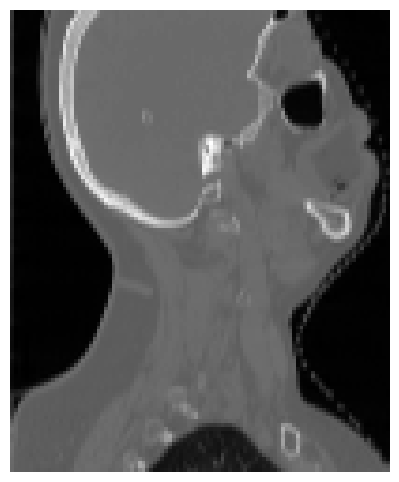

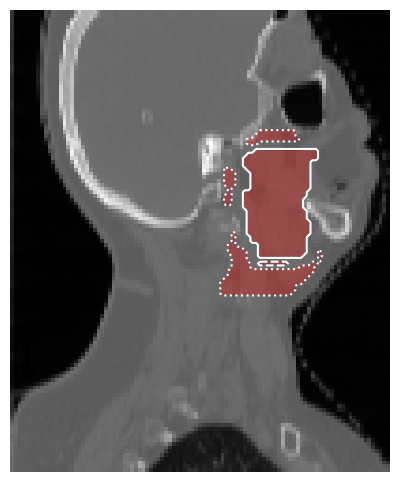

Eyes
OpticNerve_L
Brain
Lips
Lungs
Posterior_Neck
Mandible-PTV
OCavity-PTV


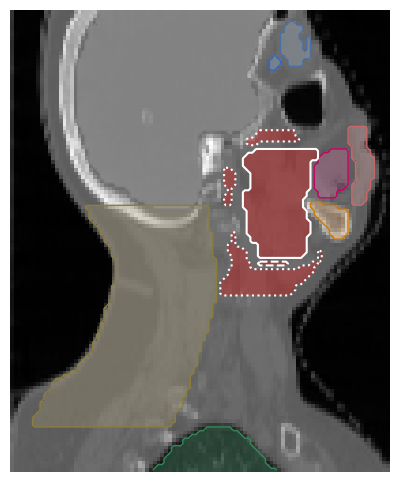

Eyes
OpticNerve_L
Brain
Lips
Lungs
Posterior_Neck
Mandible-PTV
OCavity-PTV


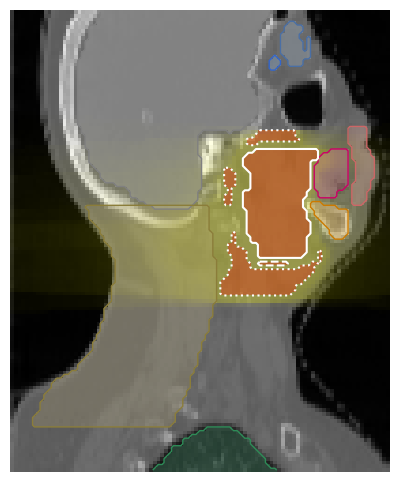

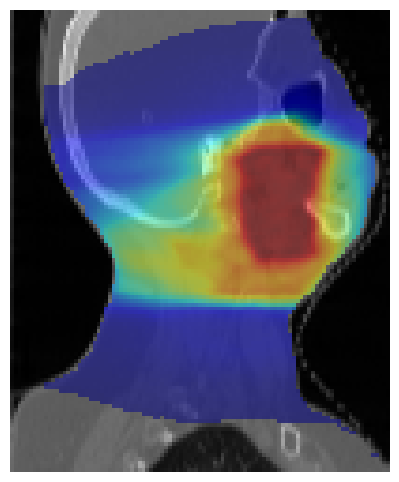

In [4]:
PTV_LINESTYLES = ['solid', 'dashed', 'dotted']  # high → low (matches results.py)
PTV_FILL_SHADES = ['#7A007A', '#CC00CC', '#FFB3FF']  # high → low magenta shades
PTV_LINE_SHADES = ['#5C005C', '#990099', '#CC66CC']

COLORS = {
    # --- Optics / Ear ---
    "Cochlea_L":        {"fill": "#99D9EA", "line": "#3399CC"},
    "Cochlea_R":        {"fill": "#66C2E0", "line": "#1F78B4"},
    "Eyes":             {"fill": "#B3CDE3", "line": "#4A6FA5"},
    "Lens_L":           {"fill": "#CCE5FF", "line": "#6699CC"},
    "Lens_R":           {"fill": "#BBD9FF", "line": "#4D88CC"},
    "OpticNerve_L":     {"fill": "#99CCFF", "line": "#3366CC"},
    "OpticNerve_R":     {"fill": "#66B2FF", "line": "#1F4FBF"},
    "Chiasm":           {"fill": "#80BFFF", "line": "#005FCC"},

    # --- Brain / CNS ---
    "Brain":            {"fill": "#D0D0D0", "line": "#808080"},
    "BrainStem_03":     {"fill": "#66FFFF", "line": "#00B3B3"},
    "SpinalCord_05":    {"fill": "#4DFFFF", "line": "#00A6A6"},

    # --- Airway / Digestive ---
    "Trachea":          {"fill": "#99E699", "line": "#339933"},
    "Esophagus":        {"fill": "#B2E6B2", "line": "#4CAF50"},
    "Larynx-PTV":       {"fill": "#FF99FF", "line": "#CC00CC"},

    # --- Thorax / Misc ---
    "Lungs":            {"fill": "#66CC99", "line": "#2E8B57"},
    "Posterior_Neck":   {"fill": "#C2B280", "line": "#8B7D3A"},
    "Shoulders":        {"fill": "#D8CFC4", "line": "#8C8273"},

    # --- Oral cavity / Jaw ---
    "Lips":             {"fill": "#FFB3B3", "line": "#CC6666"},
    "Mandible-PTV":     {"fill": "#FFB266", "line": "#CC7A00"},
    "OCavity-PTV":      {"fill": "#FF80BF", "line": "#CC0066"},

    # --- Salivary glands (PTV-related) ---
    "ParotidCon-PTV":   {"fill": "#FFB3D9", "line": "#CC3385"},
    "ParotidIps-PTV":   {"fill": "#FF99CC", "line": "#CC0066"},
    "Parotids-PTV":     {"fill": "#FF66B2", "line": "#B30059"},
    "Submand-PTV":      {"fill": "#FFCCE5", "line": "#CC6699"},
    "SubmandL-PTV":     {"fill": "#FFB3E6", "line": "#CC66B2"},
    "SubmandR-PTV":     {"fill": "#FF99D6", "line": "#B24C8C"},

    # --- Pharyngeal / Thyroid ---
    "PharConst-PTV":    {"fill": "#FF8CFF", "line": "#993399"},
    "Thyroid-PTV":      {"fill": "#E699FF", "line": "#9933CC"},
}

volume_name = 'HNSCC-01-0078+A4Ac+MOS_12319'
slice_idx = 109

# index_map is a list of [file, slice_idx] (in 3d mode, deduped by file)
volume_idx = next(
  i for i, (file, _) in enumerate(dataset.index_map)
  if file.stem == volume_name
)

structure, dose, info = dataset[volume_idx]
structure = structure.unsqueeze(0)
ct_volume = dataset.selector.get_ct(structure)

body_mask = dataset.selector.get_body(structure)[0, 0, :, :, slice_idx].numpy().astype(bool)
body_mask = np.flip(body_mask)

oar_masks = dataset.selector.get_component(structure, 'oar_v3').numpy()[0, :, :, :, slice_idx]
oar_masks = np.flip(oar_masks, axis=(1, 2))

ptv_doses = dataset.selector.get_component(structure, 'ptv_doses').numpy()[0, :, :, :, slice_idx]
ptv_doses = np.flip(ptv_doses, axis=(1, 2))

beam_plate = dataset.selector.get_component(structure, 'beam_plate').numpy()[0, 0, :, :, slice_idx]
beam_plate = np.flip(beam_plate)

dose_slice = dataset.denormalize_target(dose)[0, :, :, slice_idx].numpy()
dose_slice = np.flip(dose_slice)

ys, xs = np.where(body_mask)
ymin, ymax = ys.min(), ys.max()
xmin, xmax = xs.min(), xs.max()

ct_slice = ct_volume[0, 0, :, :, slice_idx].numpy()
ct_slice = np.flip(ct_slice)
ct_slice = ct_slice[ymin:ymax+1, xmin:xmax+1]
beam_plate_cropped = beam_plate[ymin:ymax+1, xmin:xmax+1]
dose_cropped = dose_slice[ymin:ymax+1, xmin:xmax+1]


def draw_oars(ax):
  for oar_name, oar_mask in zip(GDPHMM_OAR_V3, oar_masks):
    if not oar_mask.any():
      continue
    oar_mask = oar_mask[ymin:ymax+1, xmin:xmax+1] > 0
    print(oar_name)
    color = COLORS[oar_name]
    ax.imshow(
      np.ma.masked_where(~oar_mask, oar_mask),
      cmap=ListedColormap([color['fill']]),
      alpha=0.25,
      interpolation="nearest",
    )
    ax.contour(oar_mask, levels=[0.5], colors=[color['line']], linewidths=1)


def draw_ptvs(ax):
  # ptv_doses channels are sorted high → low (see results.py)
  for ptv_mask, fill_color, line_color, linestyle in zip(
      ptv_doses, PTV_FILL_SHADES, PTV_LINE_SHADES, PTV_LINESTYLES
  ):
    ptv_mask = ptv_mask[ymin:ymax+1, xmin:xmax+1] > 0
    if not ptv_mask.any():
      continue
    ax.imshow(
      np.ma.masked_where(~ptv_mask, ptv_mask),
      cmap=ListedColormap(['red']),
      alpha=0.3,
      interpolation="nearest",
    )
    ax.contour(
      ptv_mask, levels=[0.5], colors=['white'],
      linewidths=1.5, linestyles=[linestyle],
    )


def draw_dose(ax):
  dose_max = dose_cropped.max()
  dose_masked = np.ma.masked_where(dose_cropped < 0.01 * dose_max, dose_cropped)
  ax.imshow(dose_masked, cmap='jet', alpha=0.5, vmin=0, vmax=dose_max, interpolation='nearest')


def render(name, show_ct=True, show_dose=False, show_ptvs=False, show_oars=False, show_beam=False):
  fig, ax = plt.subplots(figsize=(6, 6))
  if show_ct:
    ax.imshow(ct_slice, cmap='gray', interpolation='nearest')
  if show_beam:
    draw_beam_overlay(ax, beam_plate_cropped)
  if show_dose:
    draw_dose(ax)
  if show_oars:
    draw_oars(ax)
  if show_ptvs:
    draw_ptvs(ax)
  ax.axis('off')
  fig.savefig(f'../imgs/defense/{name}.pdf', bbox_inches='tight', pad_inches=0)
  plt.show()


render('ct-slice')
render('ct-slice-ptvs', show_ptvs=True)
render('ct-slice-ptvs-oars', show_ptvs=True, show_oars=True)
render('ct-slice-ptvs-oars-beam', show_ptvs=True, show_oars=True, show_beam=True)
render('ct-slice-dose', show_dose=True)


In [6]:
mamba_199_pred = ModelResults('100-mamba', 'ddpm-1000', 199, 'test', dataset)
beamdiff_199_pred = ModelResults('101-beamdiff', 'ddpm-1000', 199, 'test', dataset)
spdiffdose_199_pred = ModelResults('102-spdiffdose', 'ddpm-1000', 199, 'test', dataset)
dosediff_199_pred = ModelResults('103-dosediff', 'ddpm-1000', 199, 'test', dataset)
diffdp_199_pred = ModelResults('104-diffdp', 'ddpm-1000', 199, 'test', dataset)

c3d_2d_199_pred = ModelResults('105-c3d-2d', 'unet', 199, 'test', dataset)
mednext_m_199_pred = ModelResults('152-mednext-m-l2', 'unet', 199, 'test', dataset)
deeplabv3plus_199_pred = ModelResults('147-deeplabv3plus-l2', 'unet', 199, 'test', dataset)
hdunet_199_pred = ModelResults('153-hdunet-l2', 'unet', 199, 'test', dataset)
mednext_v2_m_199_pred = ModelResults('154-mednext-v2-m-l2', 'unet', 199, 'test', dataset)

In [7]:
pred_baseline_comparison = ModelComparison(
  [mamba_199_pred, beamdiff_199_pred, spdiffdose_199_pred, dosediff_199_pred, diffdp_199_pred, c3d_2d_199_pred, mednext_m_199_pred, deeplabv3plus_199_pred, hdunet_199_pred, mednext_v2_m_199_pred],
  ['MD-Dose', 'BeamDiff', 'SP-DiffDose', 'DoseDiff', 'DiffDP', 'C3D', 'MedNeXt', 'DeepLabv3+', 'HD U-Net', 'MedNeXt v2'],
  ['DDPM'] * 5 + ['U-Net'] * 5
)

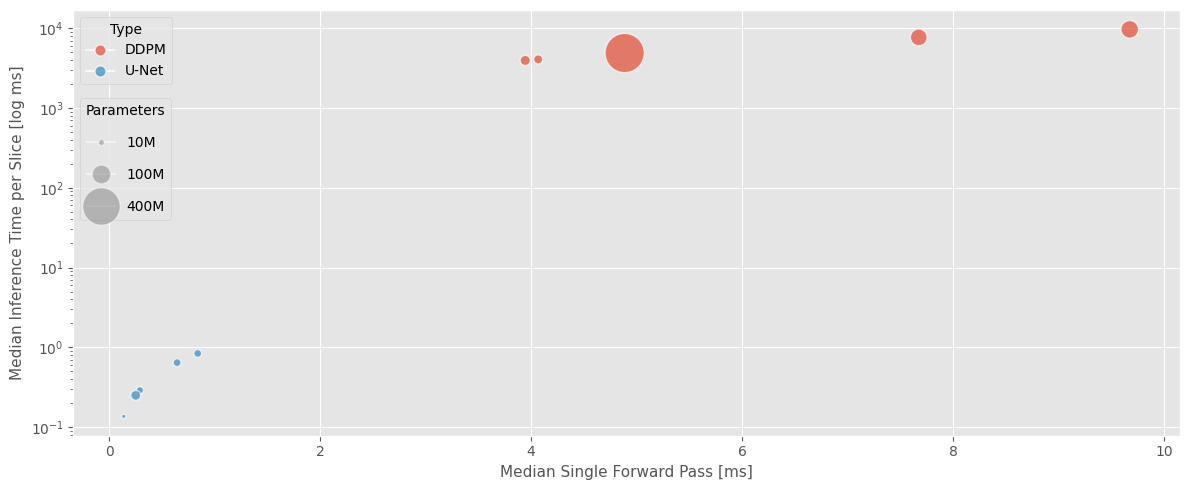

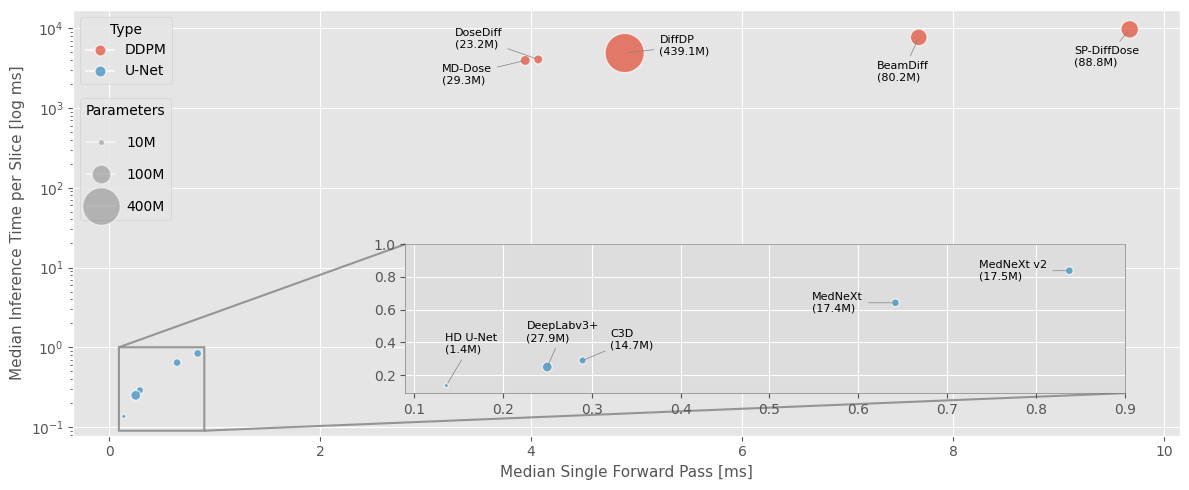

In [116]:
# Build inference time per slice data
data = []
for result, label, group in zip(pred_baseline_comparison.results_list, pred_baseline_comparison.result_labels, pred_baseline_comparison.result_groups):
  durations = result.slice_metrics['duration']
  data.append({'model': label, 'group': group, 'inference_time': durations.median()})

df = pd.DataFrame(data)

# Forward pass time: same for U-Net, /1000 for DDPM
df['forward_pass_time'] = df.apply(
  lambda r: r['inference_time'] / 1000 if r['group'] == 'DDPM' else r['inference_time'], axis=1
)
df['inference_time'] = df['inference_time'] * 1000
df['forward_pass_ms'] = df['forward_pass_time'] * 1000

# Parameter counts (mapped to model labels)
param_counts = {
  'MD-Dose':      29287392,
  'BeamDiff':     80201345,
  'SP-DiffDose':  88770801,
  'DoseDiff':     23240001,
  'DiffDP':      439128385,
  'C3D':          14725282,
  'MedNeXt':      17419202,
  'DeepLabv3+':   27913505,
  'HD U-Net':      1427815,
  'MedNeXt v2':   17474946,
}
df['params'] = df['model'].map(param_counts)
df['params_M'] = df['params'] / 1e6

size_scale = 800 / df['params_M'].max()

# Manual label offsets (x, y) in points per model
ddpm_offsets = {
  'MD-Dose':      (-60, -10),
  'BeamDiff':     (-30, -25),
  'SP-DiffDose':  (-40, -20),
  'DoseDiff':     (-60, 15),
  'DiffDP':       (25, 5),
}

inset_offsets = {
  'C3D':          (20, 15),
  'MedNeXt':      (-60, 0),
  'DeepLabv3+':   (-15, 25),
  'HD U-Net':      (-1, 30),
  'MedNeXt v2':   (-65, 0),
}

def plot_scatter(ax, df, annotate=True, offsets=None, skip_groups=None):
  for group, color in [('DDPM', '#E24A33'), ('U-Net', '#348ABD')]:
    mask = df['group'] == group
    sub = df[mask]
    ax.scatter(
      sub['forward_pass_ms'], sub['inference_time'],
      s=sub['params_M'].clip(5) * size_scale, c=color, alpha=0.7,
      edgecolors='white', linewidth=1, label=group, zorder=3
    )
  if annotate:
    for _, row in df.iterrows():
      if skip_groups and row['group'] in skip_groups:
        continue
      ofs = (offsets or {}).get(row['model'], (8, 0))
      ax.annotate(
        f"{row['model']}\n({row['params_M']:.1f}M)",
        (row['forward_pass_ms'], row['inference_time']),
        textcoords='offset points', xytext=ofs, fontsize=8, va='center',
        arrowprops=dict(arrowstyle='-', color='gray', lw=0.5) if abs(ofs[0]) > 8 or abs(ofs[1]) > 8 else None
      )

from matplotlib.lines import Line2D

def add_legends(ax):
  color_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#E24A33', markersize=8, alpha=0.7, label='DDPM'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#348ABD', markersize=8, alpha=0.7, label='U-Net'),
  ]
  size_legend_values = [10, 100, 400]
  size_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', alpha=0.5,
           markersize=np.sqrt(v * size_scale), label=f'{v:.0f}M')
    for v in size_legend_values
  ]
  leg1 = ax.legend(handles=color_handles, loc='upper left', title='Type')
  ax.add_artist(leg1)
  ax.legend(handles=size_handles, loc='center left', title='Parameters', labelspacing=1.3, bbox_to_anchor=(0, 0.65))


# Plain version: no zoom inset, no model labels
fig, ax = plt.subplots(figsize=(12, 5))
ax.set_yscale('log')
plot_scatter(ax, df, annotate=False)
ax.set_xlabel('Median Single Forward Pass [ms]')
ax.set_ylabel('Median Inference Time per Slice [log ms]')
# ax.set_title('Inference Efficiency of Dose Prediction Models')
add_legends(ax)
fig.tight_layout()
plt.savefig('../imgs/defense/pred-benchmark-efficiency-plain.pdf', bbox_inches='tight')
plt.show()


# Full version: with zoom inset and all model labels
fig, ax = plt.subplots(figsize=(12, 5))
ax.set_yscale('log')
plot_scatter(ax, df, annotate=True, offsets=ddpm_offsets, skip_groups={'U-Net'})
ax.set_xlabel('Median Single Forward Pass [ms]')
ax.set_ylabel('Median Inference Time per Slice [log ms]')
# ax.set_title('Inference Efficiency of Dose Prediction Models')
add_legends(ax)

# Inset zoom for U-Net region
unet = df[df['group'] == 'U-Net']

axins = ax.inset_axes([0.3, 0.1, 0.65, 0.35])
axins.patch.set_facecolor('#ddd')
for spine in axins.spines.values():
  spine.set_edgecolor('gray')
  spine.set_linewidth(0.5)
plot_scatter(axins, unet, annotate=True, offsets=inset_offsets)
axins.set_xlim(0.09, 0.9)
axins.set_ylim(0.09, 1)
axins.set_xlabel('')
axins.set_ylabel('')
ax.indicate_inset_zoom(axins, edgecolor='gray', alpha=0.8, linewidth=1.5)

fig.tight_layout()
plt.savefig('../imgs/defense/pred-benchmark-efficiency-full.pdf', bbox_inches='tight')
plt.show()


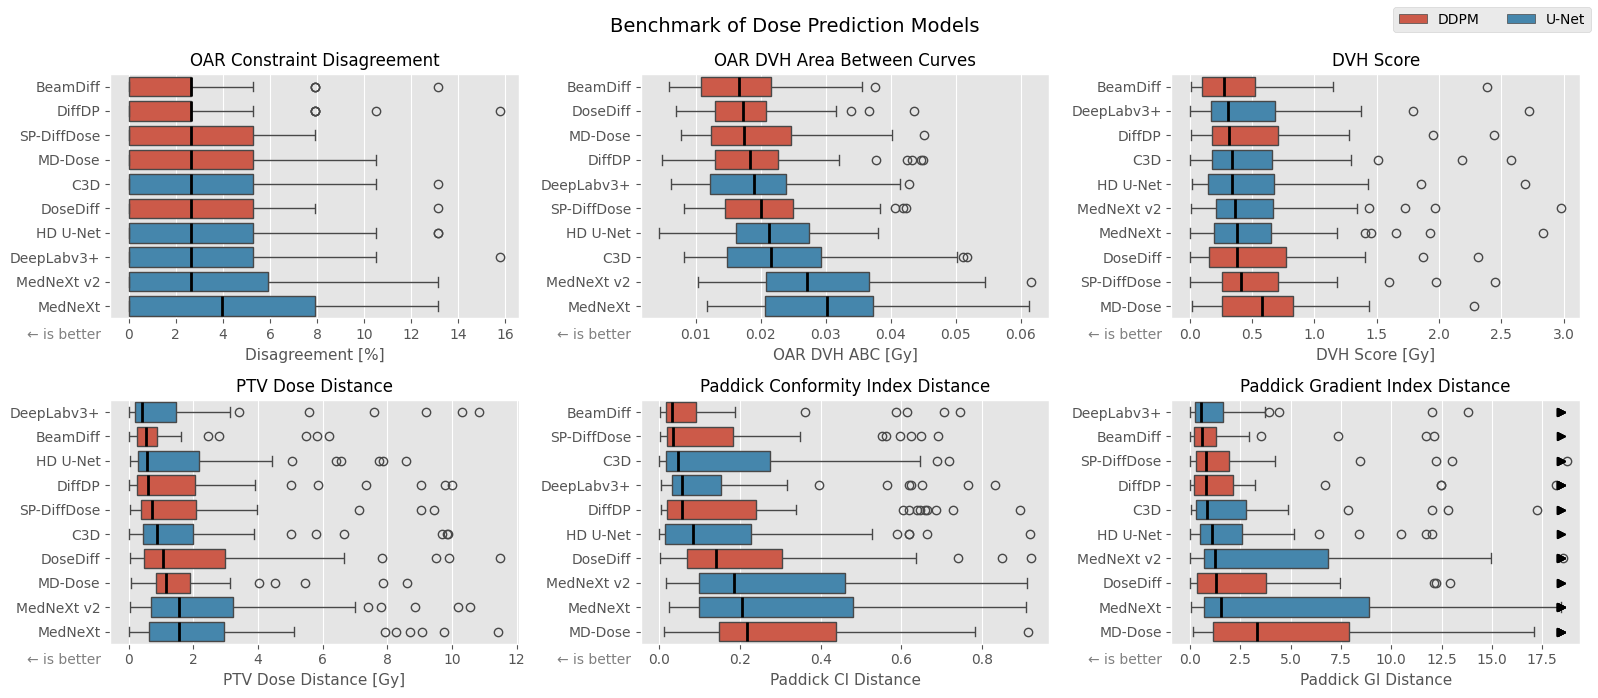

In [38]:
fig, axes = pred_baseline_comparison.plot_metric_distributions(METRICS_PRED, sort=True, outliers=METRICS_PRED[0:5])
fig.set_size_inches(FIG_WIDTH, 7)

fig.suptitle("Benchmark of Dose Prediction Models")
fig.tight_layout()
plt.savefig('../imgs/defense/pred-benchmark-metrics.pdf', bbox_inches='tight')
plt.show()

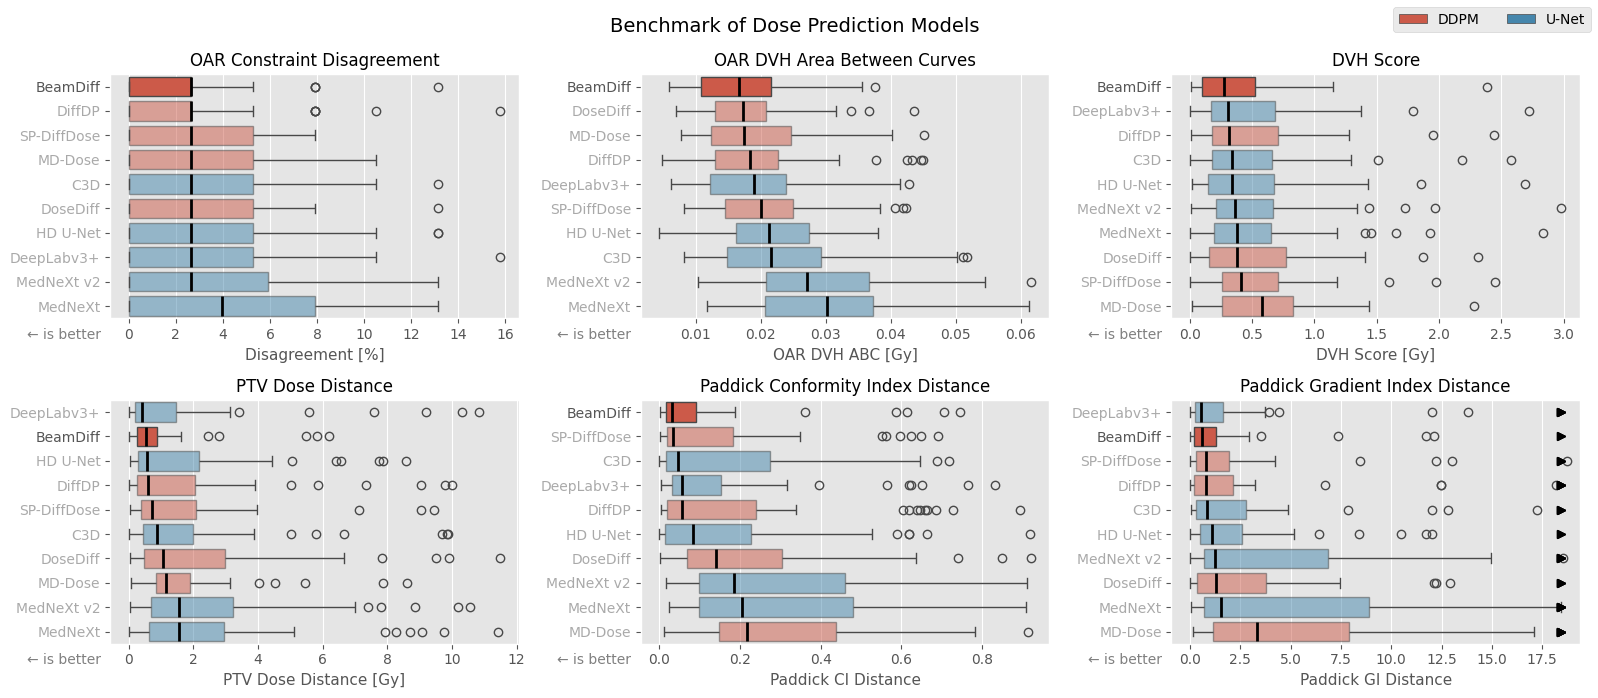

In [39]:
fig, axes = pred_baseline_comparison.plot_metric_distributions(METRICS_PRED, sort=True, outliers=METRICS_PRED[0:5], highlight='BeamDiff')
fig.set_size_inches(FIG_WIDTH, 7)

fig.suptitle("Benchmark of Dose Prediction Models")
fig.tight_layout()
plt.savefig('../imgs/defense/pred-benchmark-metrics-beamdiff.pdf', bbox_inches='tight')
plt.show()

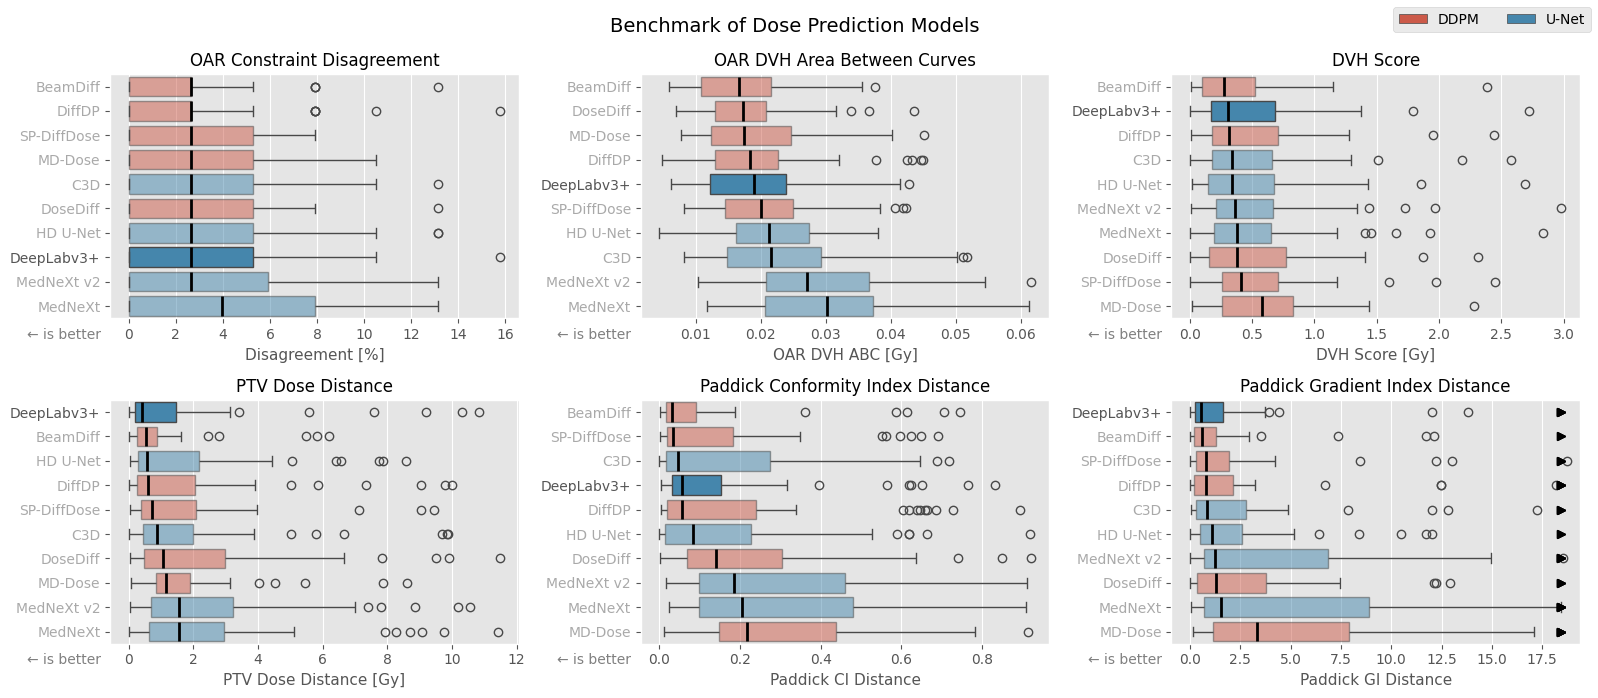

In [40]:
fig, axes = pred_baseline_comparison.plot_metric_distributions(METRICS_PRED, sort=True, outliers=METRICS_PRED[0:5], highlight='DeepLabv3+')
fig.set_size_inches(FIG_WIDTH, 7)

fig.suptitle("Benchmark of Dose Prediction Models")
fig.tight_layout()
plt.savefig('../imgs/defense/pred-benchmark-metrics-deeplabv3plus.pdf', bbox_inches='tight')
plt.show()

In [41]:
mamba_199_calc = ModelResults('200-mamba', 'ddpm-1000', 199, 'test', dataset)
beamdiff_199_calc = ModelResults('201-beamdiff', 'ddpm-1000', 199, 'test', dataset)
spdiffdose_199_calc = ModelResults('202-spdiffdose', 'ddpm-1000', 199, 'test', dataset)
dosediff_199_calc = ModelResults('203-dosediff', 'ddpm-1000', 199, 'test', dataset)
diffdp_199_calc = ModelResults('204-diffdp', 'ddpm-1000', 199, 'test', dataset)

c3d_2d_199_calc = ModelResults('205-c3d-2d', 'unet', 199, 'test', dataset)
mednext_m_199_calc = ModelResults('213-mednext-m-l2', 'unet', 199, 'test', dataset)
deeplabv3plus_199_calc = ModelResults('214-deeplabv3plus-l2', 'unet', 199, 'test', dataset)
hdunet_199_calc = ModelResults('215-hdunet-l2', 'unet', 199, 'test', dataset)
mednext_v2_m_199_calc = ModelResults('216-mednext-v2-m-l2', 'unet', 199, 'test', dataset)

In [42]:
calc_baseline_comparison = ModelComparison(
  [mamba_199_calc, beamdiff_199_calc, spdiffdose_199_calc, dosediff_199_calc, diffdp_199_calc, c3d_2d_199_calc, mednext_m_199_calc, deeplabv3plus_199_calc, hdunet_199_calc, mednext_v2_m_199_calc],
  ['MD-Dose', 'BeamDiff', 'SP-DiffDose', 'DoseDiff', 'DiffDP', 'C3D', 'MedNeXt', 'DeepLabv3+', 'HD U-Net', 'MedNeXt v2'],
  ['DDPM'] * 5 + ['U-Net'] * 5
)

calc_baseline_unet_comparison = ModelComparison(
  [c3d_2d_199_calc, deeplabv3plus_199_calc, hdunet_199_calc, mednext_m_199_calc, mednext_v2_m_199_calc],
  ['C3D', 'DeepLabv3+', 'HD U-Net', 'MedNeXt', 'MedNeXt v2'],
  ['U-Net'] * 5
)

calc_baseline_ddpm_comparison = ModelComparison(
  [beamdiff_199_calc, diffdp_199_calc, dosediff_199_calc, mamba_199_calc, spdiffdose_199_calc],
  ['BeamDiff', 'DiffDP', 'DoseDiff', 'MD-Dose', 'SP-DiffDose'],
  ['DDPM'] * 5
)

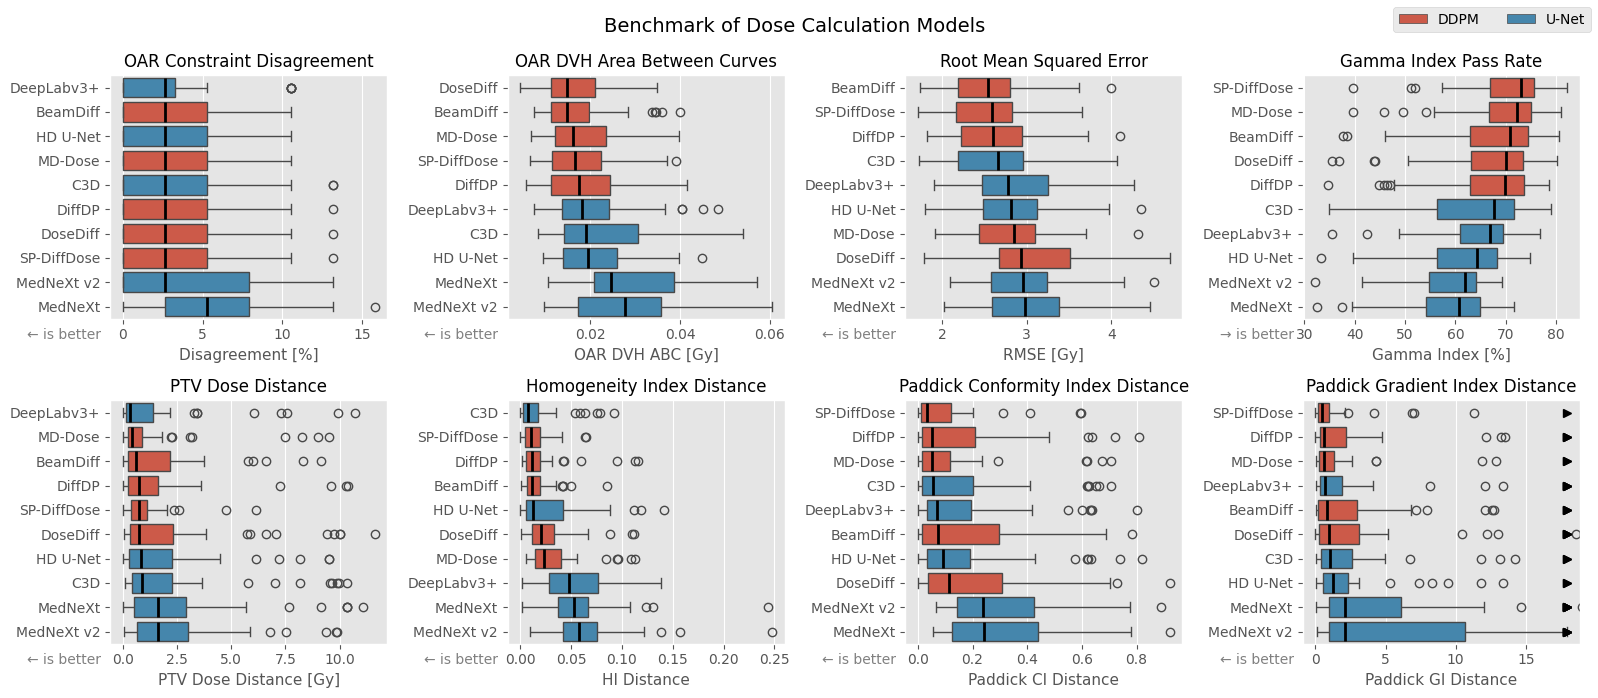

In [43]:
fig, axes = calc_baseline_comparison.plot_metric_distributions(METRICS_PLAN_EXTENDED, sort=True, outliers=METRICS_PLAN_EXTENDED[0:7])
fig.set_size_inches(FIG_WIDTH, 7)

fig.suptitle("Benchmark of Dose Calculation Models")
plt.savefig('../imgs/defense/calc-benchmark-metrics.pdf', bbox_inches='tight')
plt.show()

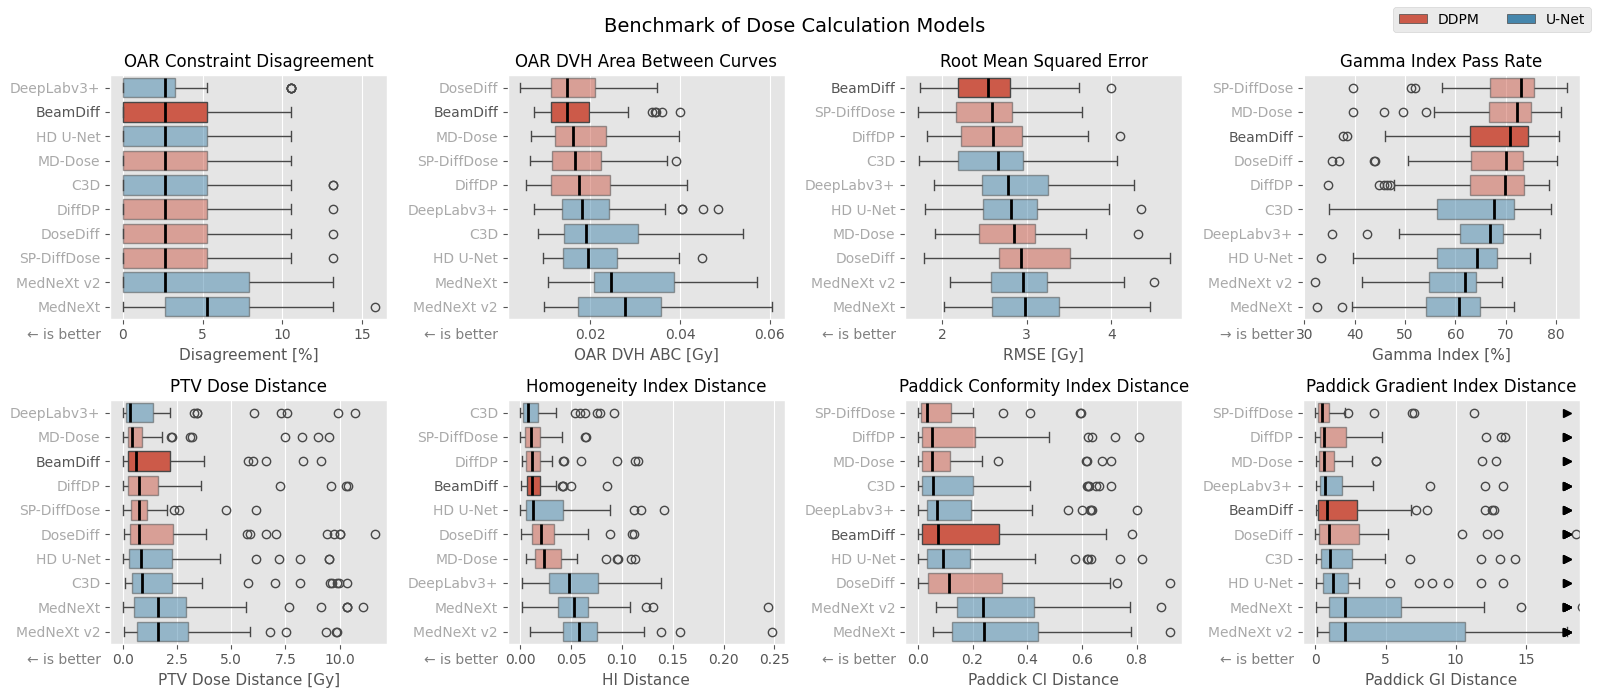

In [44]:
fig, axes = calc_baseline_comparison.plot_metric_distributions(METRICS_PLAN_EXTENDED, sort=True, outliers=METRICS_PLAN_EXTENDED[0:7], highlight='BeamDiff')
fig.set_size_inches(FIG_WIDTH, 7)

fig.suptitle("Benchmark of Dose Calculation Models")
plt.savefig('../imgs/defense/calc-benchmark-metrics-beamdiff.pdf', bbox_inches='tight')
plt.show()

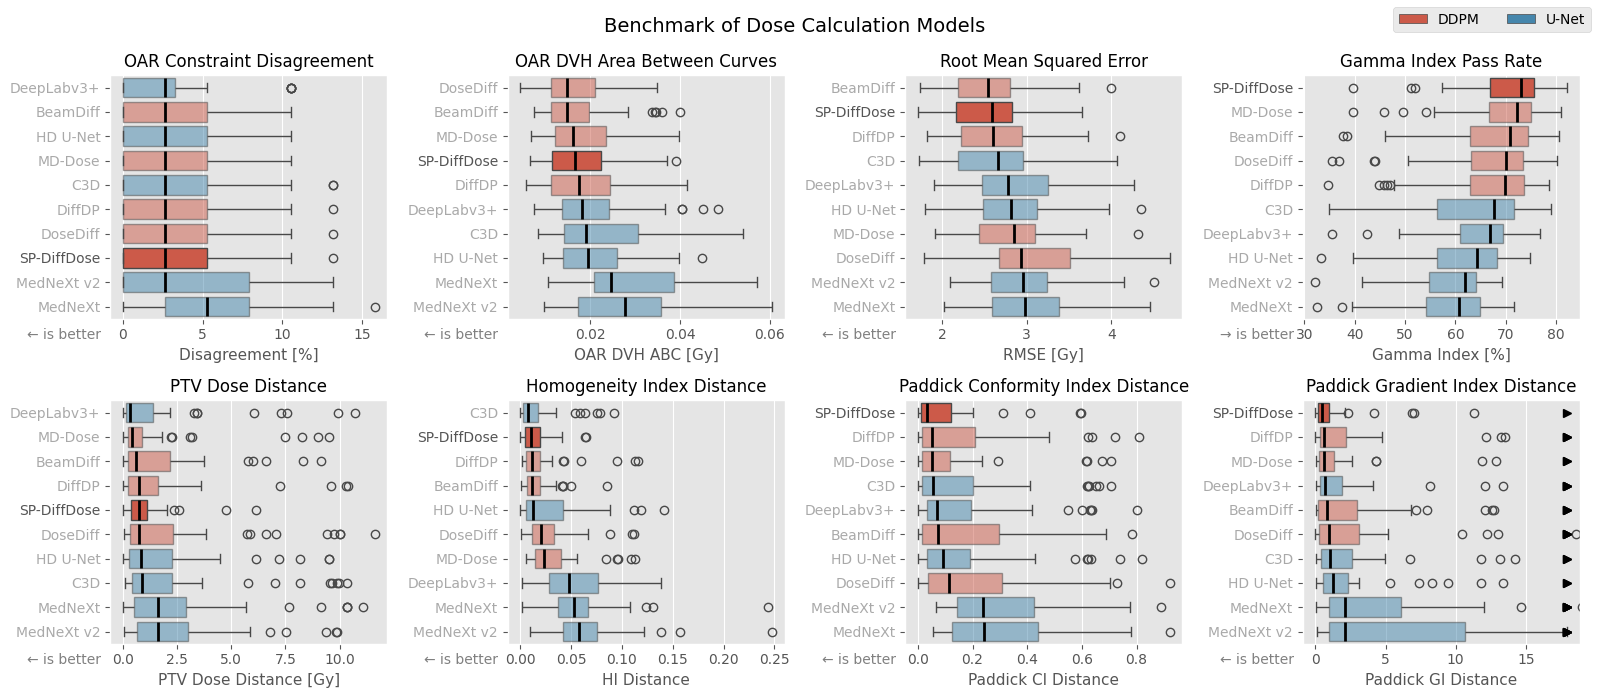

In [45]:
fig, axes = calc_baseline_comparison.plot_metric_distributions(METRICS_PLAN_EXTENDED, sort=True, outliers=METRICS_PLAN_EXTENDED[0:7], highlight='SP-DiffDose')
fig.set_size_inches(FIG_WIDTH, 7)

fig.suptitle("Benchmark of Dose Calculation Models")
plt.savefig('../imgs/defense/calc-benchmark-metrics-spdiffdose.pdf', bbox_inches='tight')
plt.show()

In [46]:
spdiffdose_task_comparison = ModelComparison(
  [spdiffdose_199_pred, spdiffdose_199_calc],
  ['Dose Prediction', 'Dose Calculation'],
  ['DDPM'] * 2
)

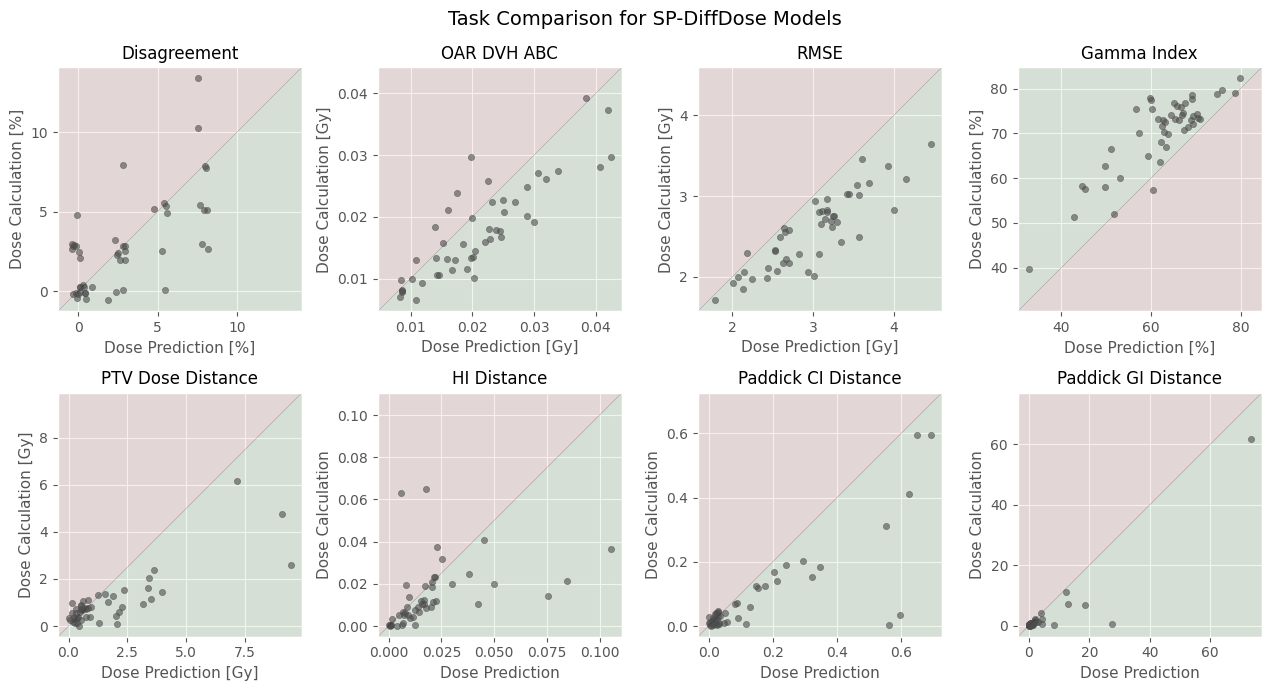

In [51]:
fig, axes = spdiffdose_task_comparison.plot_metric_scatters(
  METRICS_PLAN_EXTENDED,
  'Dose Prediction',
  'Dose Calculation',
  better_label='Dose Calculation',
  jitter=METRICS_PLAN_EXTENDED[0:1]
)
fig.set_size_inches(13, 7)

fig.suptitle('Task Comparison for SP-DiffDose Models')
fig.tight_layout()
plt.savefig('../imgs/defense/comp-spdiffdose-volumes.pdf', bbox_inches='tight')
plt.show()

In [55]:
beamdiff_task_comparison = ModelComparison(
  [beamdiff_199_pred, beamdiff_199_calc],
  ['Dose Prediction', 'Dose Calculation'],
  ['DDPM'] * 2
)

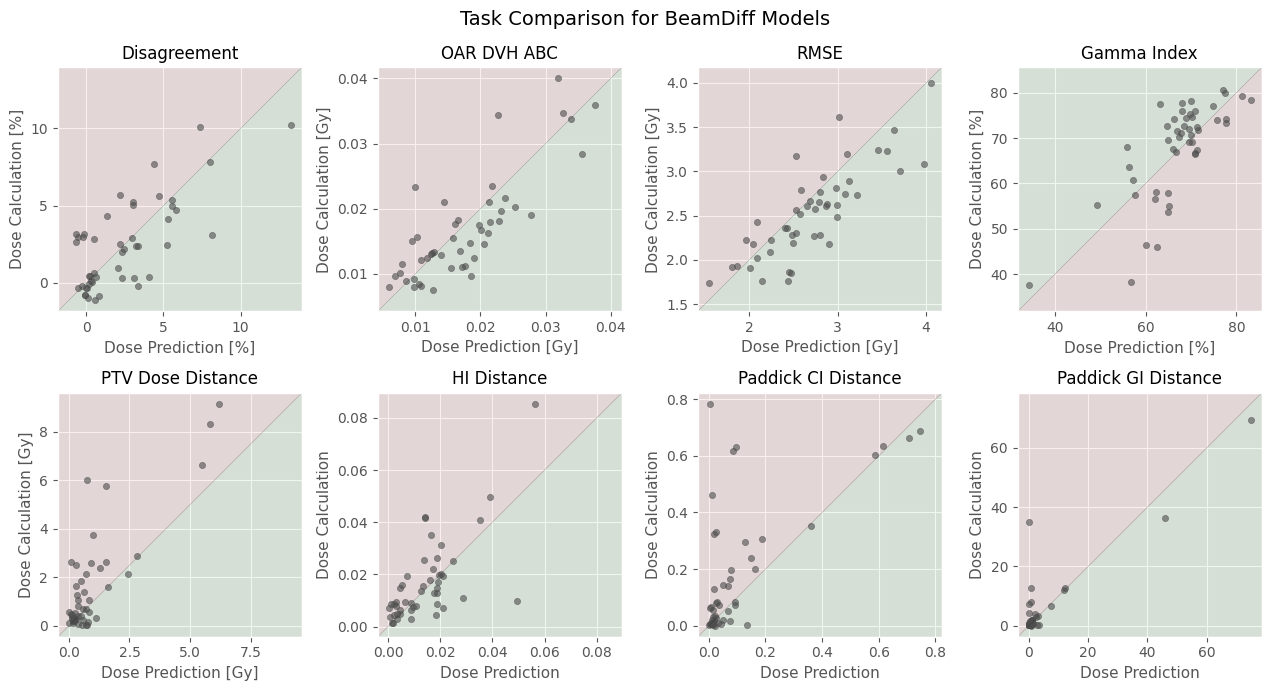

In [56]:
fig, axes = beamdiff_task_comparison.plot_metric_scatters(
  METRICS_PLAN_EXTENDED,
  'Dose Prediction',
  'Dose Calculation',
  better_label='Dose Calculation',
  jitter=METRICS_PLAN_EXTENDED[0:1]
)
fig.set_size_inches(13, 7)

fig.suptitle('Task Comparison for BeamDiff Models')
fig.tight_layout()
plt.savefig('../imgs/defense/comp-beamdiff-volumes.pdf', bbox_inches='tight')
plt.show()

In [52]:
pred_baseline_results = []

for seed in range(1, 11):
  sampling_name = f'ddpm-seed{seed}-1000' if seed > 1 else 'ddpm-1000'
  pred_baseline_results.append(ModelResults('112-beamdiff-bf16', sampling_name, 199, 'test', dataset))
  pred_baseline_results.append(ModelResults('136-beamdiff-bf16-2', sampling_name, 199, 'test', dataset))
  pred_baseline_results.append(ModelResults('137-beamdiff-bf16-3', sampling_name, 199, 'test', dataset))
  pred_baseline_results.append(ModelResults('138-beamdiff-bf16-4', sampling_name, 199, 'test', dataset))
  pred_baseline_results.append(ModelResults('139-beamdiff-bf16-5', sampling_name, 199, 'test', dataset))

pred_beamdiff_baseline_comparison = ModelComparison(pred_baseline_results, ['Model 1'] * 10 + ['Model 2'] * 10 + ['Model 3'] * 10 + ['Model 4'] * 10 + ['Model 5'] * 10, ['DDPM'] * 50)

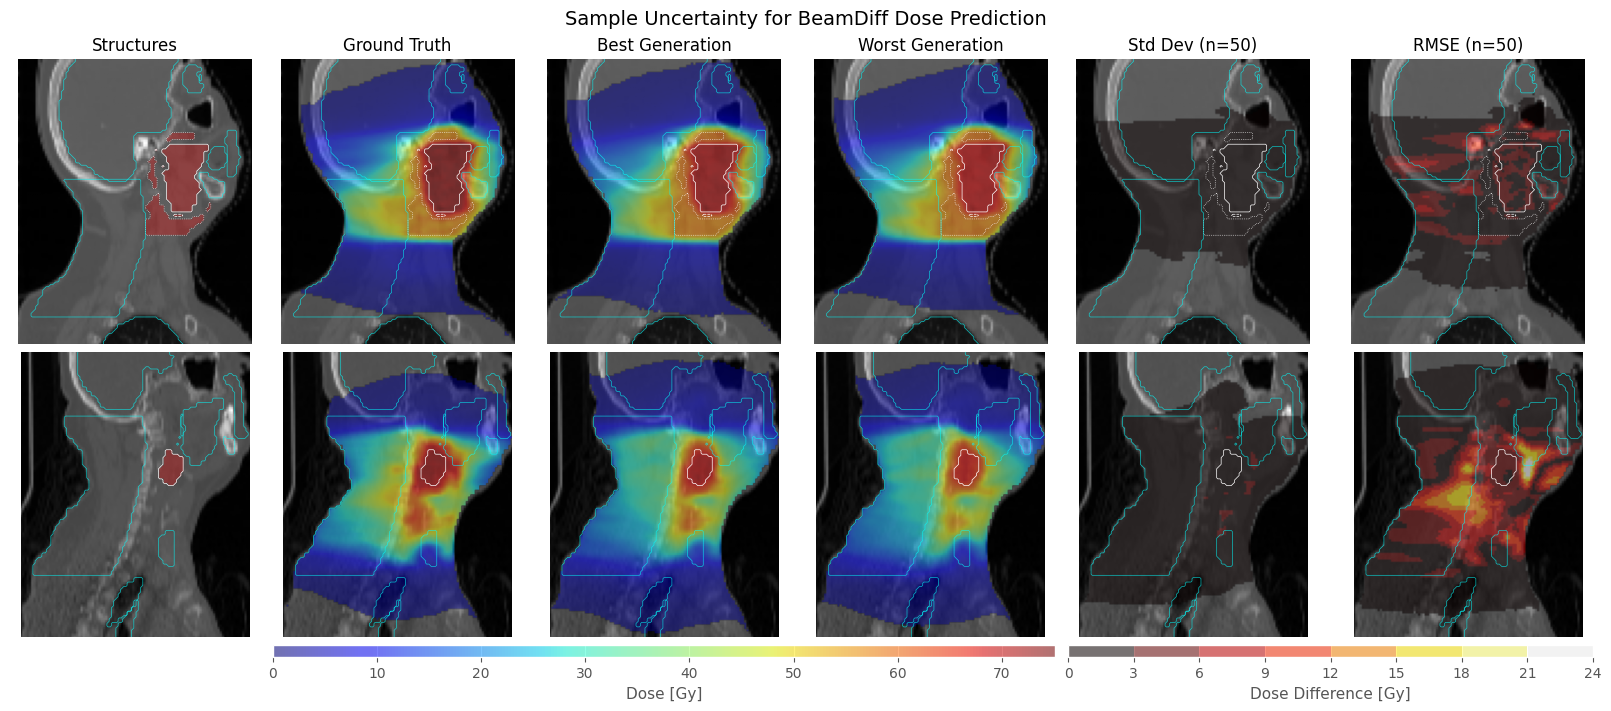

In [54]:
fig, axes = pred_beamdiff_baseline_comparison.visualise_uncertainty_with_ct([
	('HNSCC-01-0078+A4Ac+MOS_12319', 110),
	('HN-CHUM-003+S2A4Ac+MOS_20285', 90),

], crop_to_body=True, crop_padding=0, n_error_levels=8, max_error=24)

fig.set_size_inches(FIG_WIDTH, 7)
fig.suptitle('Sample Uncertainty for BeamDiff Dose Prediction')
plt.savefig('../imgs/defense/pred-beamdiff-sample-uncertainty.pdf', bbox_inches='tight')
plt.show()

In [57]:
calc_beamdiff_baseline_results = []

for seed in range(1, 11):
  sampling_name = f'ddpm-seed{seed}-1000' if seed > 1 else 'ddpm-1000'
  calc_beamdiff_baseline_results.append(ModelResults('212-beamdiff-mp', sampling_name, 199, 'test', dataset))
  calc_beamdiff_baseline_results.append(ModelResults('227-beamdiff-2', sampling_name, 199, 'test', dataset))
  calc_beamdiff_baseline_results.append(ModelResults('228-beamdiff-3', sampling_name, 199, 'test', dataset))
  calc_beamdiff_baseline_results.append(ModelResults('229-beamdiff-4', sampling_name, 199, 'test', dataset))
  calc_beamdiff_baseline_results.append(ModelResults('230-beamdiff-5', sampling_name, 199, 'test', dataset))

calc_beamdiff_baseline_comparison = ModelComparison(calc_beamdiff_baseline_results, ['Model 1'] * 10 + ['Model 2'] * 10 + ['Model 3'] * 10 + ['Model 4'] * 10 + ['Model 5'] * 10, ['DDPM'] * 50)

In [58]:
beamdiff_merged_all_calc = ModelResults('217-merged-all', 'ddpm-1000', 199, 'test', dataset)
beamdiff_merged_condition_calc = ModelResults('218-merged-condition', 'ddpm-1000', 199, 'test', dataset)
beamdiff_no_mam_calc = ModelResults('219-no-mam', 'ddpm-1000', 199, 'test', dataset)
beamdiff_no_afm_calc = ModelResults('220-no-afm', 'ddpm-1000', 199, 'test', dataset)
beamdiff_no_self_attn_calc = ModelResults('221-no-self-attn', 'ddpm-1000', 199, 'test', dataset)
beamdiff_base_channels_64_calc = ModelResults('222-base-channels-64', 'ddpm-1000', 199, 'test', dataset)
beamdiff_res_blocks_1_calc = ModelResults('223-res-blocks-1', 'ddpm-1000', 199, 'test', dataset)
beamdiff_channels_1123_calc = ModelResults('224-channels-1123', 'ddpm-1000', 199, 'test', dataset)
beamdiff_channels_11123_calc = ModelResults('225-channels-11123', 'ddpm-1000', 199, 'test', dataset)
beamdiff_no_bottleneck_attn_calc = ModelResults('240-no-bottleneck-attn', 'ddpm-1000', 199, 'test', dataset)
beamdiff_optimised_arch_calc = ModelResults('226-optimised-arch', 'ddpm-1000', 199, 'test', dataset)
beamdiff_optimised_arch2_calc = ModelResults('241-optimised-arch-2', 'ddpm-1000', 199, 'test', dataset)

In [59]:
calc_beamdiff_arch_changes_comparison = ModelComparison(
  [beamdiff_merged_all_calc, beamdiff_merged_condition_calc, beamdiff_no_mam_calc, beamdiff_no_afm_calc, beamdiff_no_self_attn_calc, beamdiff_base_channels_64_calc, beamdiff_res_blocks_1_calc, beamdiff_channels_1123_calc, beamdiff_channels_11123_calc, beamdiff_no_bottleneck_attn_calc],
  ['Merged\nEncoder', 'Merged\nConditioning', 'without MAM', 'without AFM', 'without Encoder\nSelf-Attention', '64 Base\nChannels', 'Single\nResidual Block', 'Channels\n1-1-2-3', 'Channels\n1-1-1-2-3', 'without Bottleneck\nSelf-Attention'],
  ['DDPM'] * 10
)

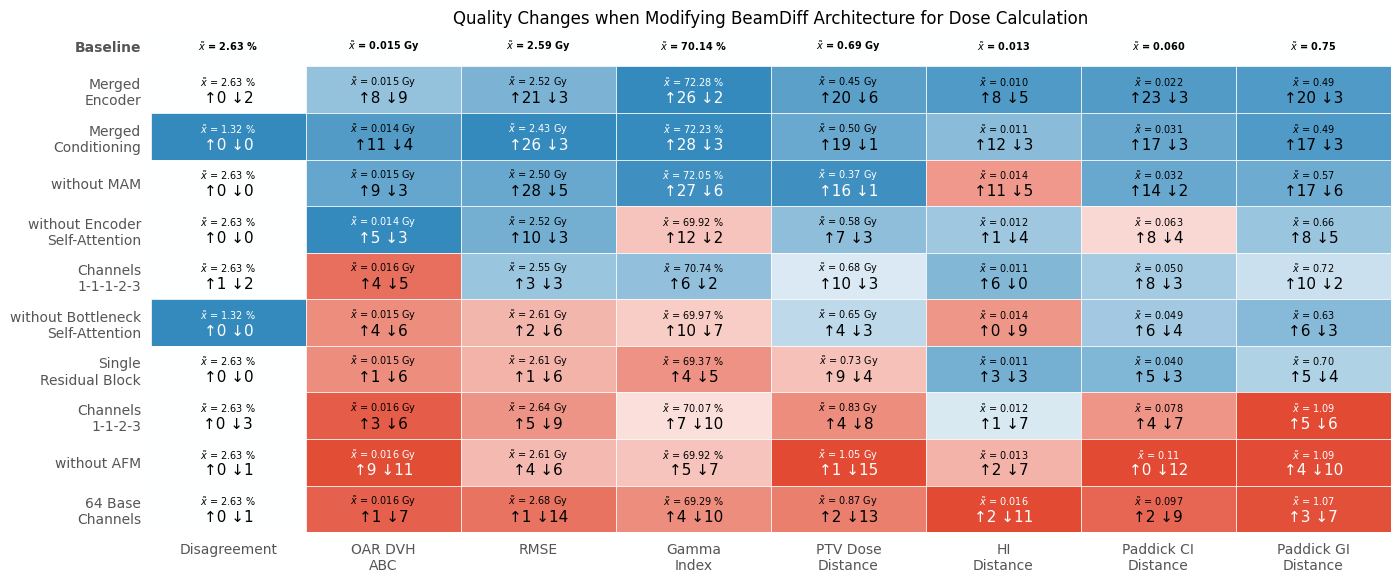

In [61]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 6.5))

_ = calc_beamdiff_arch_changes_comparison.plot_metric_heatmap(
  METRICS_PLAN_EXTENDED,
  baseline=calc_beamdiff_baseline_comparison,
  improved_q=0.975,
  worsened_q=0.025,
  sort=True,
  baseline_label='Baseline',
  ax=ax,
)

ax.set_title('Quality Changes when Modifying BeamDiff Architecture for Dose Calculation')
xticklabels = ax.get_xticklabels()
# xticklabels[0].set_text('Dis-\nagreement')
ax.set_xticklabels(xticklabels)
plt.savefig('../imgs/defense/calc-beamdiff-arch-changes-heatmap.pdf', bbox_inches='tight')
plt.show()

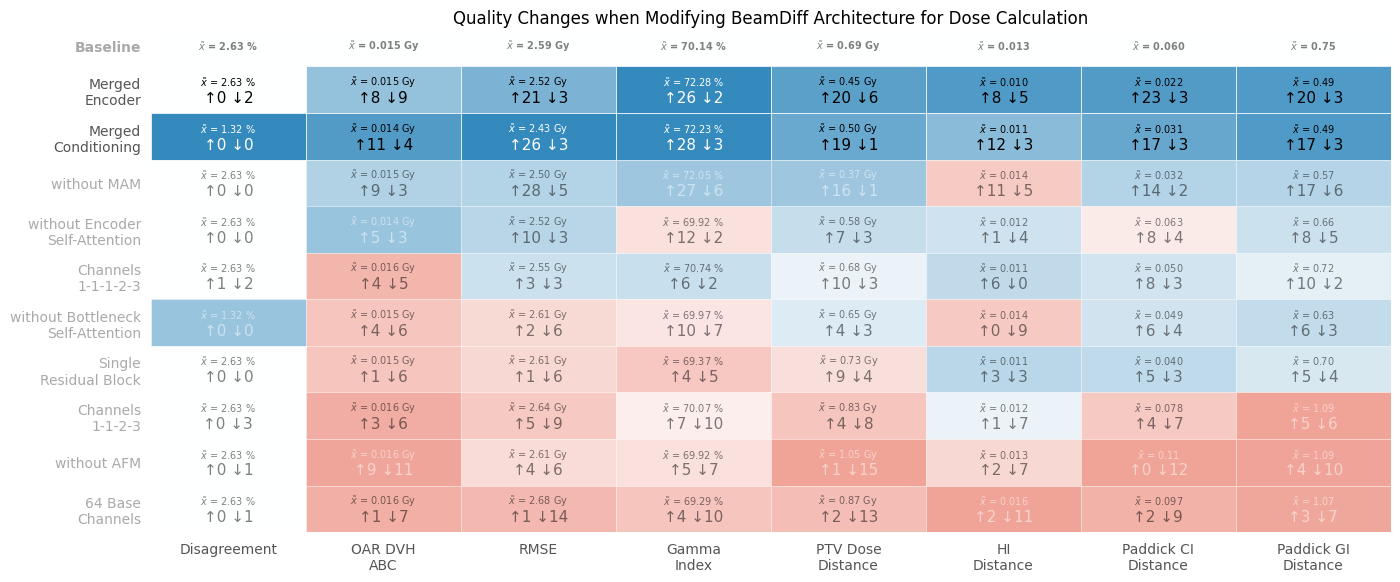

In [109]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 6.5))

_ = calc_beamdiff_arch_changes_comparison.plot_metric_heatmap(
  METRICS_PLAN_EXTENDED,
  baseline=calc_beamdiff_baseline_comparison,
  improved_q=0.975,
  worsened_q=0.025,
  sort=True,
  baseline_label='Baseline',
  ax=ax,
)

ax.set_title('Quality Changes when Modifying BeamDiff Architecture for Dose Calculation')
xticklabels = ax.get_xticklabels()
ax.set_xticklabels(xticklabels)

HIGHLIGHT_LABELS = {'Merged\nEncoder', 'Merged\nConditioning'}
muted_alpha = 0.5

yticks = list(ax.get_yticks())
yticklabels = ax.get_yticklabels()
# Baseline row has reduced height (0.6); model rows have height 1.0.
row_heights = [0.6] + [1.0] * (len(yticks) - 1)

for tick, h, label in zip(yticks, row_heights, yticklabels):
  if label.get_text() in HIGHLIGHT_LABELS:
    continue
  label.set_alpha(muted_alpha)
  y_min, y_max = tick - h / 2 - 0.05, tick + h / 2 + 0.05
  for patch in ax.patches:
    bbox = patch.get_bbox()
    y_center = (bbox.y0 + bbox.y1) / 2
    if y_min <= y_center <= y_max:
      patch.set_alpha(muted_alpha)
  for text_obj in ax.texts:
    if y_min <= text_obj.get_position()[1] <= y_max:
      text_obj.set_alpha(muted_alpha)

plt.savefig('../imgs/defense/calc-beamdiff-arch-changes-heatmap-merged-highlight.pdf', bbox_inches='tight')
plt.show()


In [62]:
beamdiff_amp_199_calc = ModelResults('212-beamdiff-mp', 'ddpm-1000', 199, 'test', dataset)

beamdiff_ddpm_500_calc = ModelResults('212-beamdiff-mp', 'ddpm-500', 199, 'test', dataset)
beamdiff_ddpm_100_calc = ModelResults('212-beamdiff-mp', 'ddpm-100', 199, 'test', dataset)
beamdiff_ddpm_50_calc = ModelResults('212-beamdiff-mp', 'ddpm-50', 199, 'test', dataset)
beamdiff_ddpm_10_calc = ModelResults('212-beamdiff-mp', 'ddpm-10', 199, 'test', dataset)
beamdiff_ddpm_5_calc = ModelResults('212-beamdiff-mp', 'ddpm-5', 199, 'test', dataset)
beamdiff_ddpm_4_calc = ModelResults('212-beamdiff-mp', 'ddpm-4', 199, 'test', dataset)
beamdiff_ddpm_3_calc = ModelResults('212-beamdiff-mp', 'ddpm-3', 199, 'test', dataset)
beamdiff_ddpm_2_calc = ModelResults('212-beamdiff-mp', 'ddpm-2', 199, 'test', dataset)
beamdiff_ddpm_1_calc = ModelResults('212-beamdiff-mp', 'ddpm-1', 199, 'test', dataset)

beamdiff_flow_1000_calc = ModelResults('231-rfm', 'flow-1000', 199, 'test', dataset)
beamdiff_flow_500_calc = ModelResults('231-rfm', 'flow-500', 199, 'test', dataset)
beamdiff_flow_100_calc = ModelResults('231-rfm', 'flow-100', 199, 'test', dataset)
beamdiff_flow_50_calc = ModelResults('231-rfm', 'flow-50', 199, 'test', dataset)
beamdiff_flow_10_calc = ModelResults('231-rfm', 'flow-10', 199, 'test', dataset)
beamdiff_flow_5_calc = ModelResults('231-rfm', 'flow-5', 199, 'test', dataset)
beamdiff_flow_4_calc = ModelResults('231-rfm', 'flow-4', 199, 'test', dataset)
beamdiff_flow_3_calc = ModelResults('231-rfm', 'flow-3', 199, 'test', dataset)
beamdiff_flow_2_calc = ModelResults('231-rfm', 'flow-2', 199, 'test', dataset)
beamdiff_flow_1_calc = ModelResults('231-rfm', 'flow-1', 199, 'test', dataset)

In [63]:
calc_beamdiff_ddpm_flow_comparison = ModelComparison(
  [beamdiff_amp_199_calc, beamdiff_ddpm_500_calc, beamdiff_ddpm_100_calc, beamdiff_ddpm_50_calc, beamdiff_ddpm_10_calc, beamdiff_ddpm_5_calc, beamdiff_ddpm_4_calc, beamdiff_ddpm_3_calc, beamdiff_ddpm_2_calc, beamdiff_ddpm_1_calc,
   beamdiff_flow_1000_calc, beamdiff_flow_500_calc, beamdiff_flow_100_calc, beamdiff_flow_50_calc, beamdiff_flow_10_calc, beamdiff_flow_5_calc, beamdiff_flow_4_calc, beamdiff_flow_3_calc, beamdiff_flow_2_calc, beamdiff_flow_1_calc],
  ['DDPM S=1000', 'DDPM S=500', 'DDPM S=100', 'DDPM S=50', 'DDPM S=10', 'DDPM S=5', 'DDPM S=4', 'DDPM S=3', 'DDPM S=2', 'DDPM S=1',
   'RFM S=1000', 'RFM S=500', 'RFM S=100', 'RFM S=50', 'RFM S=10', 'RFM S=5', 'RFM S=4', 'RFM S=3', 'RFM S=2', 'RFM S=1'],
  ['DDPM'] * 10 + ['Flow'] * 10
)

In [117]:
calc_beamdiff_ddpm_comparison = ModelComparison(
  [beamdiff_amp_199_calc, beamdiff_ddpm_500_calc, beamdiff_ddpm_100_calc, beamdiff_ddpm_50_calc, beamdiff_ddpm_10_calc, beamdiff_ddpm_5_calc, beamdiff_ddpm_4_calc, beamdiff_ddpm_3_calc, beamdiff_ddpm_2_calc, beamdiff_ddpm_1_calc],
  ['DDPM S=1000', 'DDPM S=500', 'DDPM S=100', 'DDPM S=50', 'DDPM S=10', 'DDPM S=5', 'DDPM S=4', 'DDPM S=3', 'DDPM S=2', 'DDPM S=1'],
  ['DDPM'] * 10
)

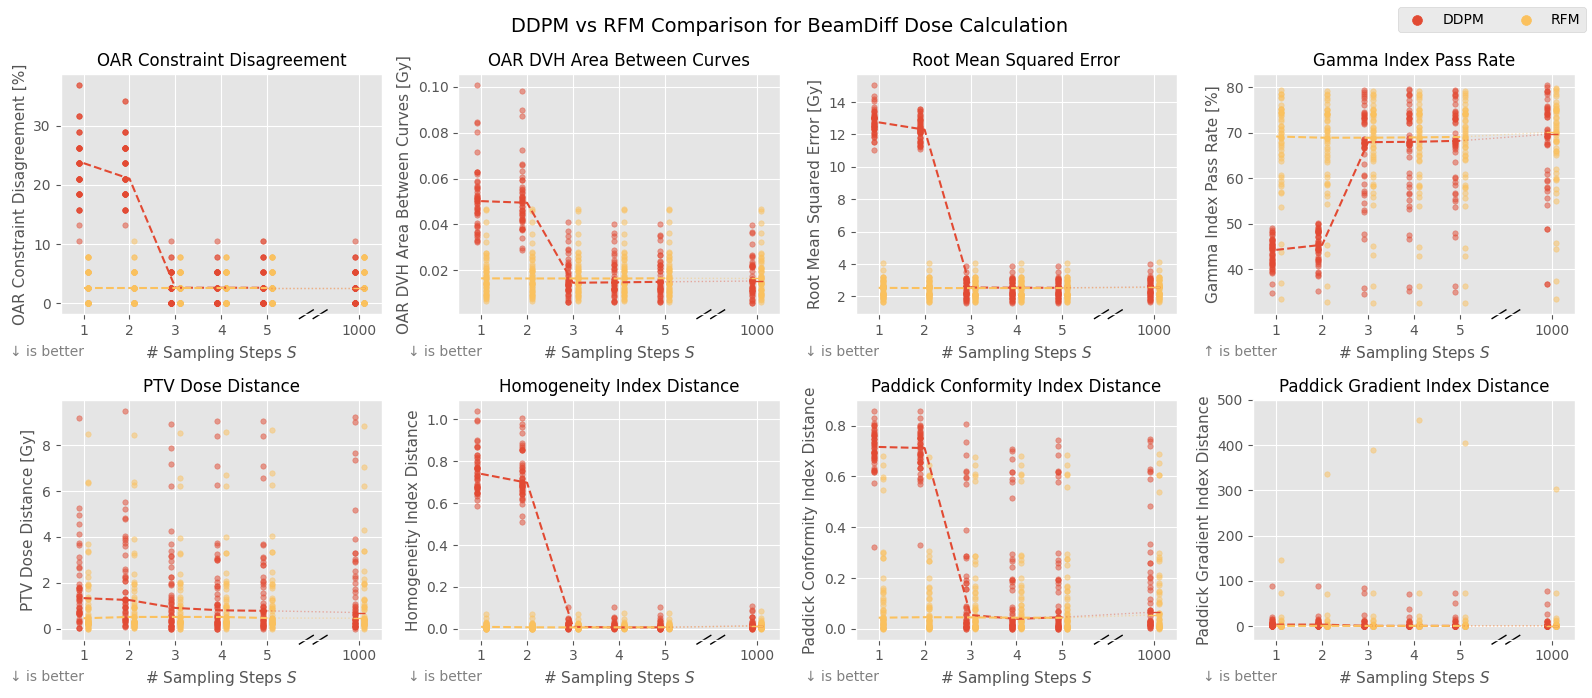

In [72]:
# Scatter plots: quality over S, DDPM vs RFM
import copy
vm = calc_beamdiff_ddpm_flow_comparison.volume_metrics.copy()

vm['method'] = vm['label'].str.extract(r'^(DDPM|RFM)')[0]
vm['steps'] = vm['label'].str.extract(r'S=(\d+)')[0].astype(int)

# Map S to x-position so S=1000 sits next to S=5 with a visible gap
S_TO_X = {1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 1000: 7}
GAP_CENTER = 6
vm = vm[vm['steps'].isin(S_TO_X.keys())].copy()
vm['x_pos'] = vm['steps'].map(S_TO_X)

# Compute medians per method and step count
medians = vm.groupby(['method', 'steps']).median(numeric_only=True)

n_metrics = len(METRICS_PLAN_EXTENDED)
n_cols = min(4, n_metrics)
n_rows = (n_metrics + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(FIG_WIDTH, 7), squeeze=False)
axes = axes.flatten()

for i, metric in enumerate(METRICS_PLAN_EXTENDED):
    ax = axes[i]

    for method, color, jitter_sign in [('DDPM', 'C0', -1), ('RFM', '#FBC15E', 1)]:
        subset = vm[vm['method'] == method]
        jittered_x = subset['x_pos'] + jitter_sign * 0.1
        ax.scatter(jittered_x, subset[metric], s=15, alpha=0.5, marker='o', c=color, label=method if i == 0 else None)

        # Median line - break across the gap so the visual jump is not misleading
        med = medians.loc[method].sort_index()
        med_low = med[med.index <= 5]
        med_high = med[med.index > 5]
        if len(med_low) > 0:
            ax.plot([S_TO_X[s] for s in med_low.index], med_low[metric],
                    color=color, linewidth=1.5, alpha=1, linestyle='dashed')
        if len(med_low) > 0 and len(med_high) > 0:
            # Faint connector across the gap
            ax.plot([S_TO_X[med_low.index[-1]], S_TO_X[med_high.index[0]]],
                    [med_low[metric].iloc[-1], med_high[metric].iloc[0]],
                    color=color, linewidth=1, alpha=0.4, linestyle='dotted')
        if len(med_high) > 0:
            ax.plot([S_TO_X[s] for s in med_high.index], med_high[metric],
                    color=color, linewidth=1.5, alpha=1, linestyle='dashed',
                    marker='_', markersize=8)

    ax.set_xlabel('# Sampling Steps $S$')
    ax.set_xlim(0.5, 7.5)
    ax.set_xticks([1, 2, 3, 4, 5, 7])
    ax.set_xticklabels(['1', '2', '3', '4', '5', '1000'])

    # Broken-axis slash marks at the gap
    trans = transforms.blended_transform_factory(ax.transData, ax.transAxes)
    slash_dx, slash_dy = 0.15, 0.018
    for xc in [GAP_CENTER - 0.15, GAP_CENTER + 0.15]:
        ax.plot([xc - slash_dx, xc + slash_dx], [-slash_dy, slash_dy],
                color='k', clip_on=False, transform=trans, linewidth=1)

    unit = get_metric_unit(metric)
    unit_suffix = f' [{unit}]' if unit else ''
    ax.set_ylabel(f'{get_metric_label(metric)}{unit_suffix}')
    ax.set_title(get_metric_label(metric))

    dir_symbol = '↑' if is_higher_better(metric) else '↓'
    ax.text(0.1, -0.185, f'{dir_symbol} is better  ', transform=ax.transAxes,
            ha='right', va='bottom', fontsize='medium', color='gray')

# Hide unused axes
for j in range(n_metrics, len(axes)):
    axes[j].set_visible(False)

axes[7].set_ylim(-30, 500)

handles, labels = axes[0].get_legend_handles_labels()
legend_handles = [copy.copy(h) for h in handles]
for h in legend_handles:
    h.set_alpha(1)
    h.set_sizes([50])
fig.legend(legend_handles, labels, loc='upper right', title='', ncol=2)
fig.suptitle('DDPM vs RFM Comparison for BeamDiff Dose Calculation')
fig.tight_layout()
plt.savefig('../imgs/defense/calc-beamdiff-ddpm-flow-volumes.pdf', bbox_inches='tight')
plt.show()

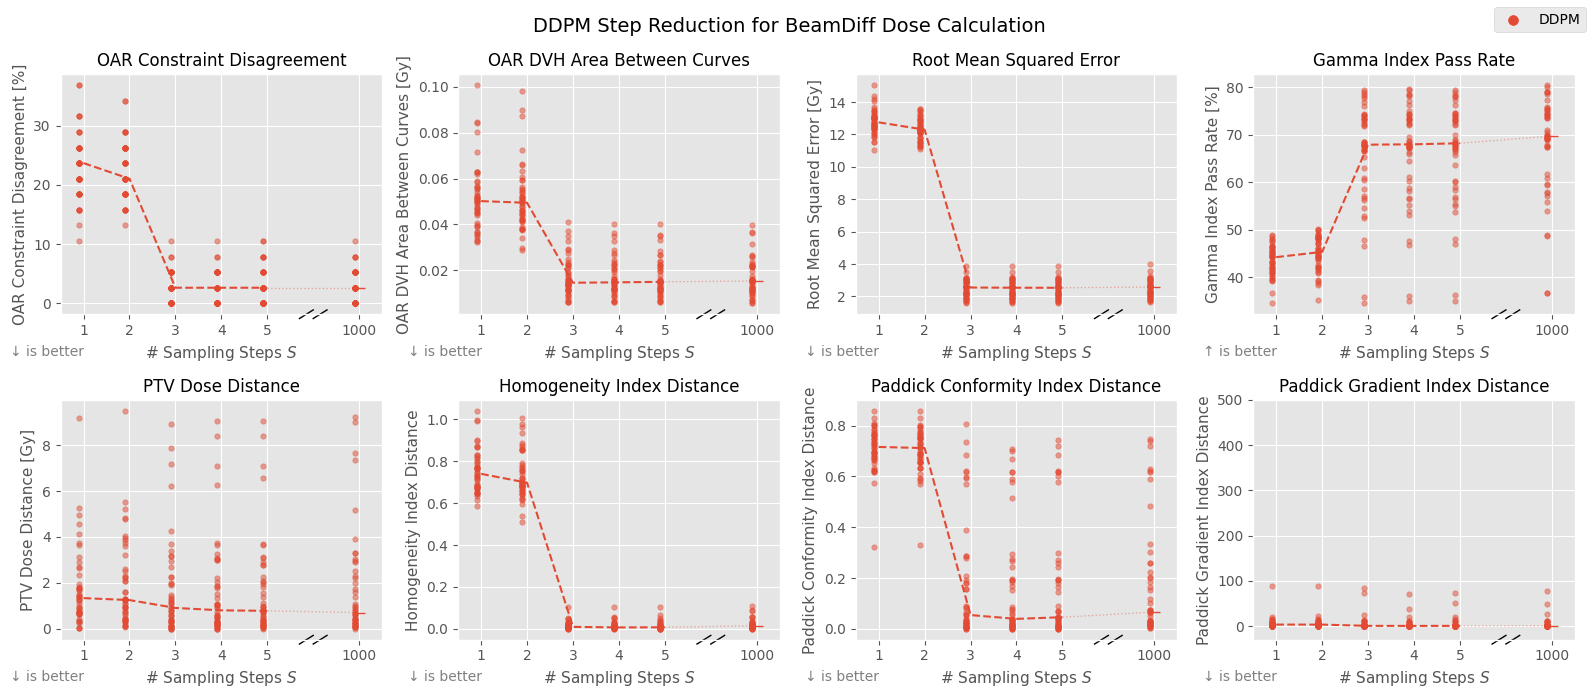

In [119]:
# Scatter plots: quality over S, DDPM
import copy
vm = calc_beamdiff_ddpm_comparison.volume_metrics.copy()

vm['method'] = vm['label'].str.extract(r'^(DDPM|RFM)')[0]
vm['steps'] = vm['label'].str.extract(r'S=(\d+)')[0].astype(int)

# Map S to x-position so S=1000 sits next to S=5 with a visible gap
S_TO_X = {1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 1000: 7}
GAP_CENTER = 6
vm = vm[vm['steps'].isin(S_TO_X.keys())].copy()
vm['x_pos'] = vm['steps'].map(S_TO_X)

# Compute medians per method and step count
medians = vm.groupby(['method', 'steps']).median(numeric_only=True)

n_metrics = len(METRICS_PLAN_EXTENDED)
n_cols = min(4, n_metrics)
n_rows = (n_metrics + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(FIG_WIDTH, 7), squeeze=False)
axes = axes.flatten()

for i, metric in enumerate(METRICS_PLAN_EXTENDED):
    ax = axes[i]

    for method, color, jitter_sign in [('DDPM', 'C0', -1)]:
        subset = vm[vm['method'] == method]
        jittered_x = subset['x_pos'] + jitter_sign * 0.1
        ax.scatter(jittered_x, subset[metric], s=15, alpha=0.5, marker='o', c=color, label=method if i == 0 else None)

        # Median line - break across the gap so the visual jump is not misleading
        med = medians.loc[method].sort_index()
        med_low = med[med.index <= 5]
        med_high = med[med.index > 5]
        if len(med_low) > 0:
            ax.plot([S_TO_X[s] for s in med_low.index], med_low[metric],
                    color=color, linewidth=1.5, alpha=1, linestyle='dashed')
        if len(med_low) > 0 and len(med_high) > 0:
            # Faint connector across the gap
            ax.plot([S_TO_X[med_low.index[-1]], S_TO_X[med_high.index[0]]],
                    [med_low[metric].iloc[-1], med_high[metric].iloc[0]],
                    color=color, linewidth=1, alpha=0.4, linestyle='dotted')
        if len(med_high) > 0:
            ax.plot([S_TO_X[s] for s in med_high.index], med_high[metric],
                    color=color, linewidth=1.5, alpha=1, linestyle='dashed',
                    marker='_', markersize=8)

    ax.set_xlabel('# Sampling Steps $S$')
    ax.set_xlim(0.5, 7.5)
    ax.set_xticks([1, 2, 3, 4, 5, 7])
    ax.set_xticklabels(['1', '2', '3', '4', '5', '1000'])

    # Broken-axis slash marks at the gap
    trans = transforms.blended_transform_factory(ax.transData, ax.transAxes)
    slash_dx, slash_dy = 0.15, 0.018
    for xc in [GAP_CENTER - 0.15, GAP_CENTER + 0.15]:
        ax.plot([xc - slash_dx, xc + slash_dx], [-slash_dy, slash_dy],
                color='k', clip_on=False, transform=trans, linewidth=1)

    unit = get_metric_unit(metric)
    unit_suffix = f' [{unit}]' if unit else ''
    ax.set_ylabel(f'{get_metric_label(metric)}{unit_suffix}')
    ax.set_title(get_metric_label(metric))

    dir_symbol = '↑' if is_higher_better(metric) else '↓'
    ax.text(0.1, -0.185, f'{dir_symbol} is better  ', transform=ax.transAxes,
            ha='right', va='bottom', fontsize='medium', color='gray')

# Hide unused axes
for j in range(n_metrics, len(axes)):
    axes[j].set_visible(False)

axes[7].set_ylim(-30, 500)

handles, labels = axes[0].get_legend_handles_labels()
legend_handles = [copy.copy(h) for h in handles]
for h in legend_handles:
    h.set_alpha(1)
    h.set_sizes([50])
fig.legend(legend_handles, labels, loc='upper right', title='', ncol=2)
fig.suptitle('DDPM Step Reduction for BeamDiff Dose Calculation')
fig.tight_layout()
plt.savefig('../imgs/defense/calc-beamdiff-ddpm-volumes.pdf', bbox_inches='tight')
plt.show()

In [73]:
beamdiff_flow_1000_pred = ModelResults('140-rfm', 'flow-1000', 199, 'test', dataset)
beamdiff_flow_500_pred = ModelResults('140-rfm', 'flow-500', 199, 'test', dataset)
beamdiff_flow_100_pred = ModelResults('140-rfm', 'flow-100', 199, 'test', dataset)
beamdiff_flow_50_pred = ModelResults('140-rfm', 'flow-50', 199, 'test', dataset)
beamdiff_flow_10_pred = ModelResults('140-rfm', 'flow-10', 199, 'test', dataset)
beamdiff_flow_5_pred = ModelResults('140-rfm', 'flow-5', 199, 'test', dataset)
beamdiff_flow_4_pred = ModelResults('140-rfm', 'flow-4', 199, 'test', dataset)
beamdiff_flow_3_pred = ModelResults('140-rfm', 'flow-3', 199, 'test', dataset)
beamdiff_flow_2_pred = ModelResults('140-rfm', 'flow-2', 199, 'test', dataset)
beamdiff_flow_1_pred = ModelResults('140-rfm', 'flow-1', 199, 'test', dataset)

beamdiff_ws_flow_100_pred = ModelResults('145-rfm-deeplabv3plus', 'flow-100', 199, 'test', dataset)
beamdiff_ws_flow_50_pred = ModelResults('145-rfm-deeplabv3plus', 'flow-50', 199, 'test', dataset)
beamdiff_ws_flow_10_pred = ModelResults('145-rfm-deeplabv3plus', 'flow-10', 199, 'test', dataset)
beamdiff_ws_flow_5_pred = ModelResults('145-rfm-deeplabv3plus', 'flow-5', 199, 'test', dataset)
beamdiff_ws_flow_4_pred = ModelResults('145-rfm-deeplabv3plus', 'flow-4', 199, 'test', dataset)
beamdiff_ws_flow_3_pred = ModelResults('145-rfm-deeplabv3plus', 'flow-3', 199, 'test', dataset)
beamdiff_ws_flow_2_pred = ModelResults('145-rfm-deeplabv3plus', 'flow-2', 199, 'test', dataset)
beamdiff_ws_flow_1_pred = ModelResults('145-rfm-deeplabv3plus', 'flow-1', 199, 'test', dataset)

In [74]:
beamdiff_flow_ws_flow_comparison = ModelComparison(
  [beamdiff_flow_100_pred, beamdiff_flow_50_pred, beamdiff_flow_10_pred, beamdiff_flow_5_pred, beamdiff_flow_4_pred, beamdiff_flow_3_pred, beamdiff_flow_2_pred, beamdiff_flow_1_pred,
   beamdiff_ws_flow_100_pred, beamdiff_ws_flow_50_pred, beamdiff_ws_flow_10_pred, beamdiff_ws_flow_5_pred, beamdiff_ws_flow_4_pred, beamdiff_ws_flow_3_pred, beamdiff_ws_flow_2_pred, beamdiff_ws_flow_1_pred],
  ['RFM S=100', 'RFM S=50', 'RFM S=10', 'RFM S=5', 'RFM S=4', 'RFM S=3', 'RFM S=2', 'RFM S=1',
   'WS-RFM S=100', 'WS-RFM S=50', 'WS-RFM S=10', 'WS-RFM S=5', 'WS-RFM S=4', 'WS-RFM S=3', 'WS-RFM S=2', 'WS-RFM S=1'],
  ['RFM'] * 8 + ['WS-RFM'] * 8
)

In [75]:
beamdiff_amp_199_pred = ModelResults('139-beamdiff-bf16-5', 'ddpm-1000', 199, 'test', dataset)

beamdiff_ddpm_500_pred = ModelResults('112-beamdiff-bf16', 'ddpm-500', 199, 'test', dataset)
beamdiff_ddpm_100_pred = ModelResults('112-beamdiff-bf16', 'ddpm-100', 199, 'test', dataset)
beamdiff_ddpm_50_pred = ModelResults('112-beamdiff-bf16', 'ddpm-50', 199, 'test', dataset)
beamdiff_ddpm_10_pred = ModelResults('112-beamdiff-bf16', 'ddpm-10', 199, 'test', dataset)
beamdiff_ddpm_5_pred = ModelResults('112-beamdiff-bf16', 'ddpm-5', 199, 'test', dataset)
beamdiff_ddpm_4_pred = ModelResults('112-beamdiff-bf16', 'ddpm-4', 199, 'test', dataset)
beamdiff_ddpm_3_pred = ModelResults('112-beamdiff-bf16', 'ddpm-3', 199, 'test', dataset)
beamdiff_ddpm_2_pred = ModelResults('112-beamdiff-bf16', 'ddpm-2', 199, 'test', dataset)
beamdiff_ddpm_1_pred = ModelResults('112-beamdiff-bf16', 'ddpm-1', 199, 'test', dataset)


In [76]:
beamdiff_wsd_ddpm_1000_pred = ModelResults('133-wsd', 'ddpm-1000', 199, 'test', dataset)
beamdiff_wsd_ddpm_500_pred = ModelResults('133-wsd', 'ddpm-500', 199, 'test', dataset)
beamdiff_wsd_ddpm_100_pred = ModelResults('133-wsd', 'ddpm-100', 199, 'test', dataset)
beamdiff_wsd_ddpm_50_pred = ModelResults('133-wsd', 'ddpm-50', 199, 'test', dataset)
beamdiff_wsd_ddpm_10_pred = ModelResults('133-wsd', 'ddpm-10', 199, 'test', dataset)
beamdiff_wsd_ddpm_5_pred = ModelResults('133-wsd', 'ddpm-5', 199, 'test', dataset)
beamdiff_wsd_ddpm_4_pred = ModelResults('133-wsd', 'ddpm-4', 199, 'test', dataset)
beamdiff_wsd_ddpm_3_pred = ModelResults('133-wsd', 'ddpm-3', 199, 'test', dataset)
beamdiff_wsd_ddpm_2_pred = ModelResults('133-wsd', 'ddpm-2', 199, 'test', dataset)
beamdiff_wsd_ddpm_1_pred = ModelResults('133-wsd', 'ddpm-1', 199, 'test', dataset)

In [77]:
beamdiff_ddpm_wsd_comparison = ModelComparison(
  [beamdiff_amp_199_pred, beamdiff_ddpm_500_pred, beamdiff_ddpm_100_pred, beamdiff_ddpm_50_pred, beamdiff_ddpm_10_pred, beamdiff_ddpm_5_pred, beamdiff_ddpm_4_pred, beamdiff_ddpm_3_pred, beamdiff_ddpm_2_pred, beamdiff_ddpm_1_pred,
   beamdiff_wsd_ddpm_1000_pred, beamdiff_wsd_ddpm_500_pred, beamdiff_wsd_ddpm_100_pred, beamdiff_wsd_ddpm_50_pred, beamdiff_wsd_ddpm_10_pred, beamdiff_wsd_ddpm_5_pred, beamdiff_wsd_ddpm_4_pred, beamdiff_wsd_ddpm_3_pred, beamdiff_wsd_ddpm_2_pred, beamdiff_wsd_ddpm_1_pred],
  ['DDPM S=1000', 'DDPM S=500', 'DDPM S=100', 'DDPM S=50', 'DDPM S=10', 'DDPM S=5', 'DDPM S=4', 'DDPM S=3', 'DDPM S=2', 'DDPM S=1',
   'WSD S=1000', 'WSD S=500', 'WSD S=100', 'WSD S=50', 'WSD S=10', 'WSD S=5', 'WSD S=4', 'WSD S=3', 'WSD S=2', 'WSD S=1'],
  ['DDPM'] * 10 + ['WSD DDPM'] * 10
)

In [78]:
beamdiff_ddpm_wsd_filtered_comparison = beamdiff_ddpm_wsd_comparison - beamdiff_amp_199_pred - beamdiff_ddpm_500_pred - beamdiff_wsd_ddpm_1000_pred - beamdiff_wsd_ddpm_500_pred

/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1759: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_bot.legend(fontsize='small')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1759: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_bot.legend(fontsize='small')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1759: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_bot.legend(fontsize='small')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1759: UserWarning: No artists with labels found to put in legend.  Note that artists w

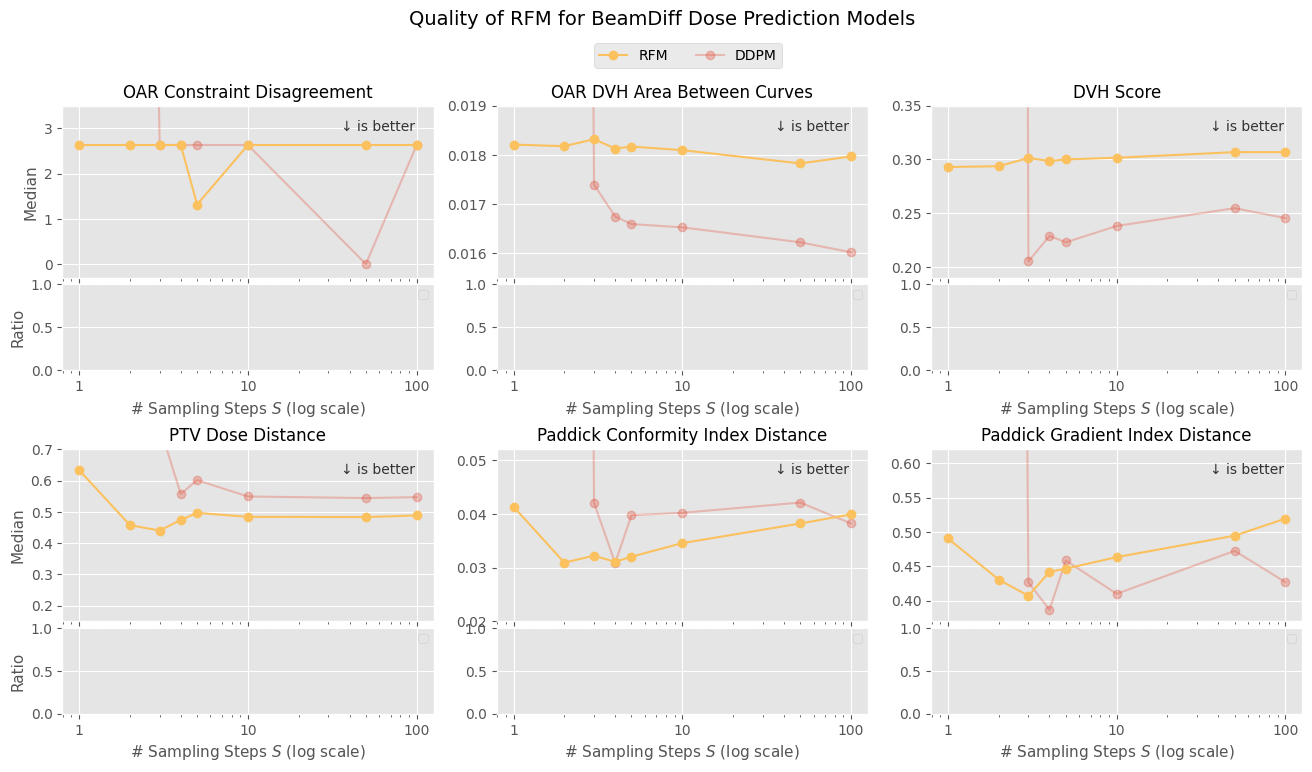

In [124]:
beamdiff_flow_only_comparison = beamdiff_flow_ws_flow_comparison - [
    beamdiff_ws_flow_100_pred, beamdiff_ws_flow_50_pred, beamdiff_ws_flow_10_pred, beamdiff_ws_flow_5_pred,
    beamdiff_ws_flow_4_pred, beamdiff_ws_flow_3_pred, beamdiff_ws_flow_2_pred, beamdiff_ws_flow_1_pred,
]
beamdiff_ddpm_only_comparison = beamdiff_ddpm_wsd_filtered_comparison - [
    beamdiff_wsd_ddpm_100_pred, beamdiff_wsd_ddpm_50_pred, beamdiff_wsd_ddpm_10_pred, beamdiff_wsd_ddpm_5_pred,
    beamdiff_wsd_ddpm_4_pred, beamdiff_wsd_ddpm_3_pred, beamdiff_wsd_ddpm_2_pred, beamdiff_wsd_ddpm_1_pred,
]

fig, all_axes = beamdiff_flow_only_comparison.plot_quality_over_T_paired(
    METRICS_PRED, agg='median', xscale='log', show_uncertainty=False, n_col_legend=4,
    colors={'RFM': '#FBC15E'},
    background=beamdiff_ddpm_only_comparison, bg_alpha=0.3,
    bg_colors={'DDPM': '#E24A33'},
)
fig.set_size_inches(16, 8)

for ax_top, ax_bot in all_axes:
    for ax in [ax_top, ax_bot]:
        ax.set_xticks([1, 10, 100])
        ax.set_xlabel('# Sampling Steps $S$ (log scale)')

all_axes[0][0].set_ylim(-0.3, 3.5)
all_axes[1][0].set_ylim(0.0155, 0.019)
all_axes[2][0].set_ylim(0.19, 0.35)
all_axes[3][0].set_ylim(0.15, 0.7)
all_axes[4][0].set_ylim(0.02, 0.052)
all_axes[5][0].set_ylim(0.37, 0.62)

all_axes[0][1].set_ylabel('Ratio')
all_axes[3][1].set_ylabel('Ratio')

fig.suptitle(
    'Quality of RFM for BeamDiff Dose Prediction Models',
    y=0.99,
)

# Access the outer GridSpec and move subplots down for legend space
outer_gs = fig.axes[0].get_gridspec().get_topmost_subplotspec().get_gridspec()
outer_gs.update(top=0.87)

legend = fig.legends[0]
legend.set_bbox_to_anchor((0.43, 0.92))
legend.set_loc('upper center')

plt.savefig('../imgs/defense/pred-beamdiff-flow-metrics.pdf', bbox_inches='tight')
plt.show()

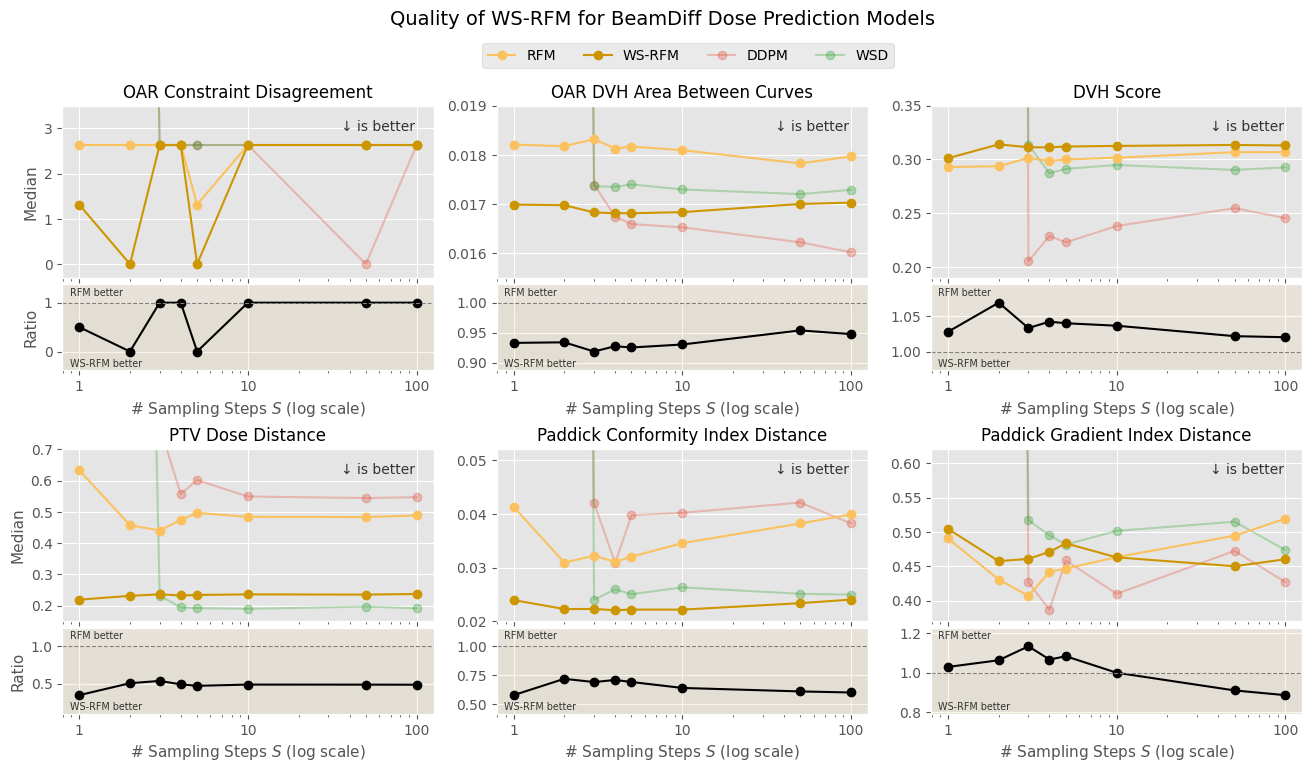

In [121]:
fig, all_axes = beamdiff_flow_ws_flow_comparison.plot_quality_over_T_paired(
    METRICS_PRED, agg='median', xscale='log', show_uncertainty=False, n_col_legend=4,
    colors={'RFM': '#FBC15E', 'WS-RFM': "#CD9600"},
    background=beamdiff_ddpm_wsd_filtered_comparison, bg_alpha=0.3,
    bg_colors={'DDPM': '#E24A33', 'WSD': '#2CA02C'},
)
fig.set_size_inches(16, 8)

for ax_top, ax_bot in all_axes:
    for ax in [ax_top, ax_bot]:
        ax.set_xticks([1, 10, 100])
        ax.set_xlabel('# Sampling Steps $S$ (log scale)')

all_axes[0][0].set_ylim(-0.3, 3.5)
all_axes[1][0].set_ylim(0.0155, 0.019)
all_axes[2][0].set_ylim(0.19, 0.35)
all_axes[3][0].set_ylim(0.15, 0.7)
all_axes[4][0].set_ylim(0.02, 0.052)
all_axes[5][0].set_ylim(0.37, 0.62)

fig.suptitle(
    'Quality of WS-RFM for BeamDiff Dose Prediction Models',
    y=0.99,
)

# Access the outer GridSpec and move subplots down for legend space
outer_gs = fig.axes[0].get_gridspec().get_topmost_subplotspec().get_gridspec()
outer_gs.update(top=0.87)

legend = fig.legends[0]
legend.set_bbox_to_anchor((0.43, 0.92))
legend.set_loc('upper center')

plt.savefig('../imgs/defense/pred-beamdiff-flow-vs-ws-flow-metrics.pdf', bbox_inches='tight')
plt.show()

In [95]:
beamdiff_best_pred = ModelResults('165-ws-rfm-combi-fp32', 'flow-cache-beamdiff-enc2-interval5-20-200-inf-2-bf16-amp', 199, 'test', dataset)
beamdiff_best_calc = ModelResults('244-rfm-combi-fp32', 'flow-cache-beamdiff-enc2-interval3-10-100-100-1-bf16-amp', 199, 'test', dataset)

In [96]:
pred_beamdiff_best_ddpm_unet_comparison = ModelComparison(
  [beamdiff_199_pred, beamdiff_best_pred, deeplabv3plus_199_pred],
  ['DDPM\nS=1000', 'WS-RFM\nS=2', 'DeepLabv3+'],
  ['DDPM', 'WS-RFM', 'U-Net']
)

pred_beamdiff_best_comparison = ModelComparison(
  [beamdiff_best_pred],
  ['WS-RFM S=2'],
  ['WS-RFM']
)

In [97]:
calc_beamdiff_best_ddpm_unet_comparison = ModelComparison(
  [beamdiff_199_calc, beamdiff_best_calc, deeplabv3plus_199_calc],
  ['DDPM\nS=1000', 'RFM\nS=1', 'DeepLabv3+'],
  ['DDPM', 'RFM', 'U-Net']
)

calc_beamdiff_best_comparison = ModelComparison(
  [beamdiff_best_calc],
  ['RFM S=1'],
  ['RFM']
)

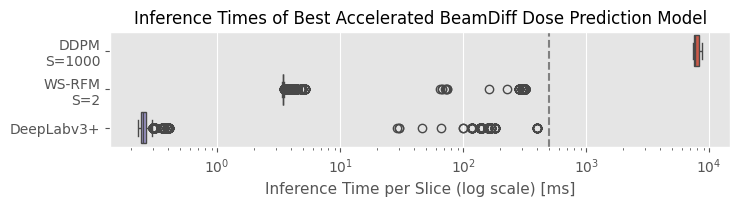

In [127]:
fig, ax = plt.subplots(figsize=(8, 1.5))
pred_beamdiff_best_ddpm_unet_comparison.plot_inference_times('slice', 'milliseconds', ax=ax)
ax.axvline(500, color='gray', linestyle='--', label='Target 0.5s/slice')
ax.legend().remove()
ax.set_title('Inference Times of Best Accelerated BeamDiff Dose Prediction Model')
ax.set_xlabel('Inference Time per Slice (log scale) [ms]')
ax.set_xscale('log')
ax.invert_yaxis()
plt.savefig('../imgs/defense/pred-beamdiff-best-inference-times.pdf', bbox_inches='tight')
plt.show()

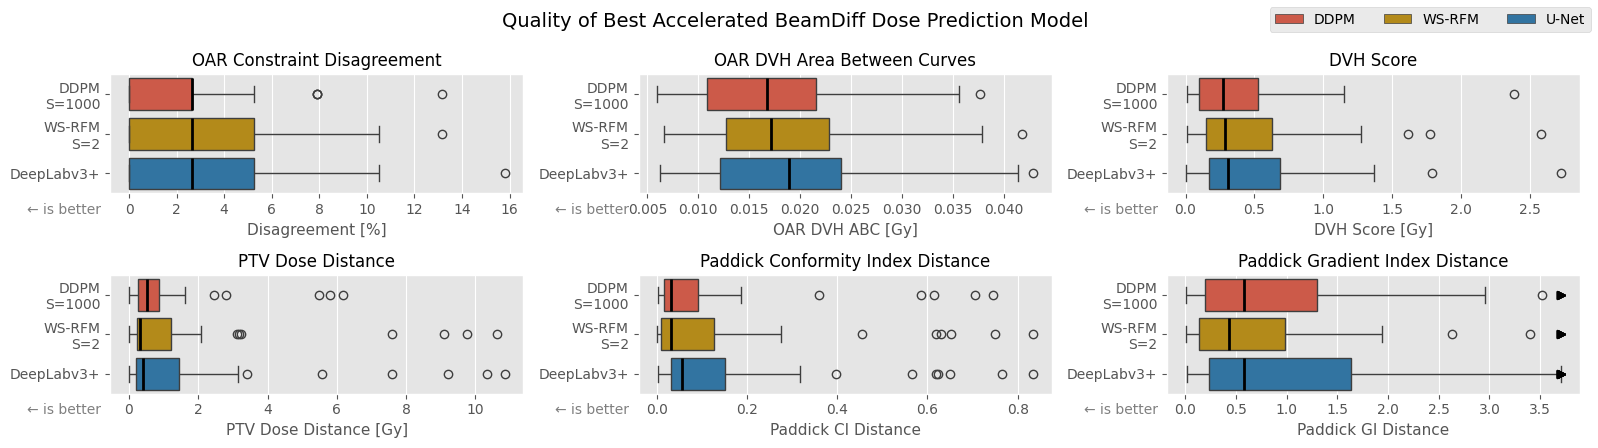

In [105]:
fig, axes = pred_beamdiff_best_ddpm_unet_comparison.plot_metric_distributions(
  METRICS_PRED, sort=False, outliers=METRICS_PRED[0:5],
  colors={'DDPM': '#E24A33', 'WS-RFM': "#CD9600", 'U-Net': '#1f77b4'},
)

fig.set_size_inches(FIG_WIDTH, 4.5)
fig.suptitle("Quality of Best Accelerated BeamDiff Dose Prediction Model")
fig.tight_layout()
plt.savefig('../imgs/defense/pred-beamdiff-best-metrics.pdf', bbox_inches='tight')
plt.show()

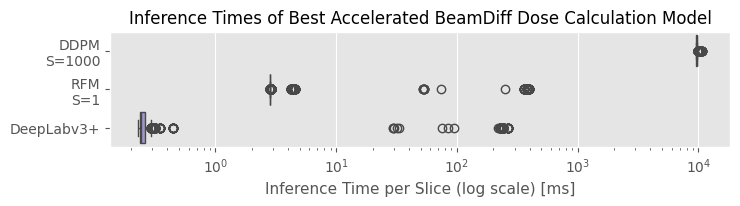

In [128]:
fig, ax = plt.subplots(figsize=(8, 1.5))
calc_beamdiff_best_ddpm_unet_comparison.plot_inference_times('slice', 'milliseconds', ax=ax)
ax.legend().remove()
ax.set_title('Inference Times of Best Accelerated BeamDiff Dose Calculation Model')
ax.set_xlabel('Inference Time per Slice (log scale) [ms]')
ax.set_xscale('log')
ax.invert_yaxis()
plt.savefig('../imgs/defense/calc-beamdiff-best-inference-times.pdf', bbox_inches='tight')
plt.show()

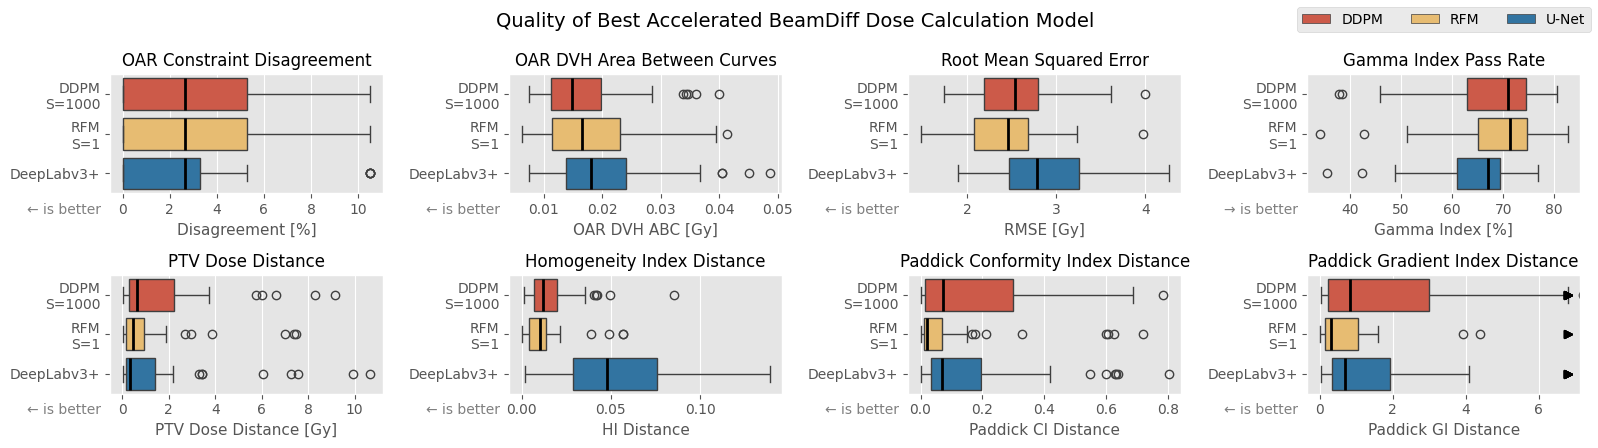

In [ ]:
fig, axes = calc_beamdiff_best_ddpm_unet_comparison.plot_metric_distributions(
  METRICS_PLAN_EXTENDED, sort=False, outliers=METRICS_PLAN_EXTENDED[0:7],
  colors={'DDPM': '#E24A33', 'RFM': '#FBC15E', 'U-Net': '#1f77b4'},
)

fig.set_size_inches(FIG_WIDTH, 4.5)
fig.suptitle("Quality of Best Accelerated BeamDiff Dose Calculation Model")
fig.tight_layout()
plt.savefig('../imgs/defense/calc-beamdiff-best-metrics.pdf', bbox_inches='tight')
plt.show()